# CO2 prediction from environmental data

## 1. Setup
imports, constants and sensor names used throughout the notebook

In [ ]:
%pip install -q pandas numpy scikit-learn matplotlib

import json
import os
import time
import cProfile
import pickle
import pstats
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from src.co2_model import parse_jsondata, deduplicate, chronological_split, scale_features, score

# ------------------------------------------------------------------ constants
DATA_PATH = "data/raw/5EnvSensor_MayToDec2024_180kRows.csv"
LOCAL_TZ = "Australia/Melbourne"      # timestamps are stored in UTC; room occupancy follows local time
TRAIN_FRAC = 0.8                      # chronological split: first 80% train, last 20% test
TARGET = "co2"

# The two sensors that pass the data audit (Section 3)
UPPER_COMPACTUS = 6012002000869
UNKNOWN_ROOM = 6012002000326
sensor_names = {
    UPPER_COMPACTUS: "Upper Compactus",
    UNKNOWN_ROOM: "Unknown Room",
}

# Model inputs (after renaming in Section 4)
features = ["humidity", "pressure", "temperature", "voc", "pm1", "pm4", "pm2_5", "pm10", "hour"]

# Frozen SVR hyperparameters, from the Section 7 grid searches and epsilon sweep
baseline_params = {"C": 1, "gamma": 0.1, "epsilon": 0.1}      # untuned starting values
final_params = {
    UNKNOWN_ROOM:    {"C": 10,   "gamma": 0.1, "epsilon": 5},    # optimum bracketed in C and gamma
    UPPER_COMPACTUS: {"C": 1e-4, "gamma": 100, "epsilon": 0.5},  # plateau: collapses to a constant prediction
}

# Raw column name -> clean name
COLUMN_RENAMES = {
    "Carbon dioxide": "co2",
    "Temperature": "temperature",
    "Humidity": "humidity",
    "Pressure": "pressure",
    "Formaldehyde": "formaldehyde",
    "Light Volatile Organic Compounds": "voc",
    "Particulate matter 1": "pm1",
    "Particulate matter 4": "pm4",
    "Particulate matter 2.5": "pm2_5",
    "Particulate matter 10": "pm10",
}
PM_RAW = ["Particulate matter 1", "Particulate matter 4", "Particulate matter 2.5", "Particulate matter 10"]

# Heavily duplicated sensor used as the evidence case in the data audit
AUDIT_SENSOR = 6012002000241
AUDIT_DEVICE_TIME = 1702273965

## 2. Loading and parsing

In [85]:
df_raw = pd.read_csv(DATA_PATH)
print(df_raw.shape)
df_raw.head()

(179447, 8)


,id,sensorid,devicetype,jsondata,status,processing_errors,createdate,processdate
0,2,6012002000241,env,"[{""values"": [{""time"": 1702273965, ""value"": 4.1...",Processed,NaN,2024-02-29 03:11:58.210358+11,2024-02-29 03:11:58.210358+11
1,4,6012002000241,env,"[{""values"": [{""time"": 1702273965, ""value"": 4.1...",Processed,NaN,2024-02-29 17:09:08.833822+11,2024-02-29 17:09:08.833822+11
2,5,6012002000326,env,"[{""values"": [{""time"": 1702270857, ""value"": 4.1...",Processed,NaN,2024-02-29 17:09:12.444245+11,2024-02-29 17:09:12.444245+11
3,16,6012002000777,env,"[{""values"": [{""time"": 1683326565, ""value"": 4.1...",Processed,NaN,2024-02-29 17:10:24.443407+11,2024-02-29 17:10:24.443407+11
4,24,6012002000869,env,"[{""values"": [{""time"": 1709186696, ""value"": 4.1...",Processed,NaN,2024-02-29 17:11:11.348578+11,2024-02-29 17:11:11.348578+11


In [86]:
parsed_rows = df_raw.apply(parse_jsondata, axis=1)
df_env = pd.DataFrame(list(parsed_rows))
print(df_env.shape)
df_env.head()

(179447, 14)


,sensorid,timestamp,device_time,Battery,Carbon dioxide,Humidity,Formaldehyde,Pressure,Temperature,Light Volatile Organic Compounds,Particulate matter 1,Particulate matter 4,Particulate matter 2.5,Particulate matter 10
0,6012002000241,2024-02-29 03:11:58.210358+11,1702273965,4.1875,603,66,6.0,1011,23.8,14.0,8.0,9.0,9.0,9.0
1,6012002000241,2024-02-29 17:09:08.833822+11,1702273965,4.1875,603,66,6.0,1011,23.8,14.0,8.0,9.0,9.0,9.0
2,6012002000326,2024-02-29 17:09:12.444245+11,1702270857,4.1875,525,68,5.0,1012,23.8,7.0,6.0,6.0,6.0,6.0
3,6012002000777,2024-02-29 17:10:24.443407+11,1683326565,4.1562,425,51,1.0,1015,18.8,71.0,1.0,3.0,3.0,4.0
4,6012002000869,2024-02-29 17:11:11.348578+11,1709186696,4.1250,465,56,17.0,1010,24.3,0.0,2.0,2.0,2.0,2.0


## 3. Data auditing

### 3.1 Timestamp decision


In [87]:
# One conversion, handling the mixed +11/+10 offsets: everything is held in UTC and converted to local time only when needed.
df_env['timestamp'] = pd.to_datetime(df_env['timestamp'], utc=True)
print(df_env['timestamp'].dtype)
print(df_env['timestamp'].min(), '->', df_env['timestamp'].max())

# Keep a copy BEFORE de-duplication, for demonstrating the data quality issue
df_env_with_dupes = df_env.copy()

datetime64[us, UTC]
2024-02-28 16:11:58.210358+00:00 -> 2026-04-22 13:20:33.199878+00:00


### 3.2 Investigating duplicates

In [88]:
# Do rows share (sensorid, device_time)? And when they do, are they identical in every other column?
duplicates = df_env_with_dupes.duplicated(subset=['sensorid', 'device_time'], keep=False)
print(f"Duplicate rows: {duplicates.sum()}")

compare_cols = [c for c in df_env_with_dupes.columns if c != 'timestamp']
key_dupes = df_env_with_dupes[duplicates]
fully_identical = key_dupes.duplicated(subset=compare_cols, keep=False).sum()
print(f"Of {len(key_dupes)} rows sharing sensorid+device_time, {fully_identical} are identical in every other column")

Duplicate rows: 136996
Of 136996 rows sharing sensorid+device_time, 136996 are identical in every other column


In [89]:
# How many rows share each (sensorid, device_time) pair, and how far apart in createdate were the re-inserts?
group_sizes = df_env_with_dupes.groupby(['sensorid', 'device_time']).size()
print(group_sizes.value_counts().sort_index())

dupe_groups = df_env_with_dupes[duplicates]
time_spread = dupe_groups.groupby(['sensorid', 'device_time'])['timestamp'].agg(lambda x: x.max() - x.min())
print(time_spread.describe())

1        42451
2          299
3           37
4           26
5            9
6            2
7            4
8            2
9            1
10           1
11           1
16           1
19           1
22           1
25           1
10926        1
15431        1
21363        1
29342        2
29566        1
Name: count, dtype: int64
count                         392
mean       2 days 15:56:08.012893
std       22 days 10:25:49.077020
min        0 days 00:00:02.597510
25%        0 days 00:08:23.510879
50%        0 days 00:10:37.513971
75%        0 days 00:10:47.792948
max      227 days 03:06:27.015886
Name: timestamp, dtype: object


In [90]:
# Does anything vary inside the biggest duplicate groups? (Battery as a probe)
biggest = dupe_groups.groupby(['sensorid', 'device_time']).size().sort_values(ascending=False).head(6).index
for sid, dtime in biggest:
    group = df_env_with_dupes[(df_env_with_dupes['sensorid'] == sid) & (df_env_with_dupes['device_time'] == dtime)]
    print(f"Sensor {sid}, device_time {dtime}: {len(group)} rows, {group['Battery'].nunique()} unique Battery values")

# One audit group in detail: the window over which a single reading was re-inserted
group_data = df_env_with_dupes[(df_env_with_dupes['sensorid'] == AUDIT_SENSOR) &
                               (df_env_with_dupes['device_time'] == AUDIT_DEVICE_TIME)]
print(f"\nAudit group (sensor {AUDIT_SENSOR}, device_time {AUDIT_DEVICE_TIME}): {len(group_data)} rows")
print(group_data['timestamp'].min(), '->', group_data['timestamp'].max())
print('Re-insert window:', group_data['timestamp'].max() - group_data['timestamp'].min())

Sensor 6012002000241, device_time 1747660084: 29566 rows, 1 unique Battery values
Sensor 6012002000241, device_time 1702273965: 29342 rows, 1 unique Battery values
Sensor 6012002000326, device_time 1702270857: 29342 rows, 1 unique Battery values
Sensor 6012002000227, device_time 1702271273: 21363 rows, 1 unique Battery values
Sensor 6012002000869, device_time 1718300744: 15431 rows, 1 unique Battery values
Sensor 6012002000777, device_time 1683326565: 10926 rows, 1 unique Battery values

Audit group (sensor 6012002000241, device_time 1702273965): 29342 rows
2024-02-28 16:11:58.210358+00:00 -> 2024-10-10 04:55:45.402148+00:00
Re-insert window: 224 days 12:43:47.191790


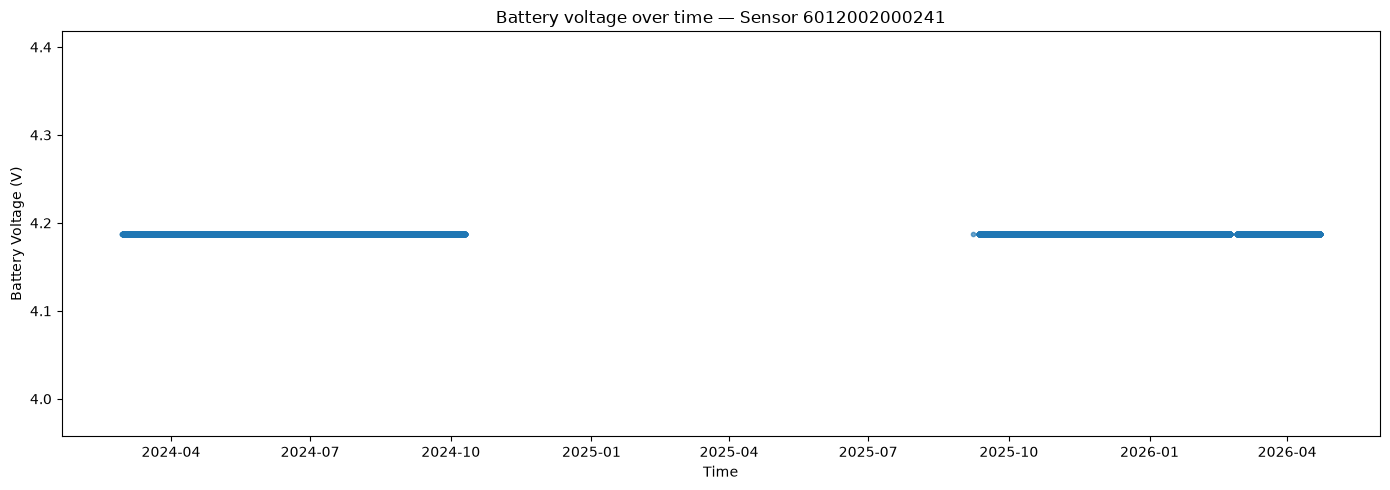

In [91]:
audit_raw = df_env_with_dupes[df_env_with_dupes['sensorid'] == AUDIT_SENSOR].sort_values('timestamp')

plt.figure(figsize=(14, 5))
plt.plot(audit_raw['timestamp'], audit_raw['Battery'], marker='.', linestyle='none', alpha=0.4)
plt.xlabel('Time')
plt.ylabel('Battery Voltage (V)')
plt.title(f'Battery voltage over time — Sensor {AUDIT_SENSOR}')
plt.tight_layout()
plt.show()

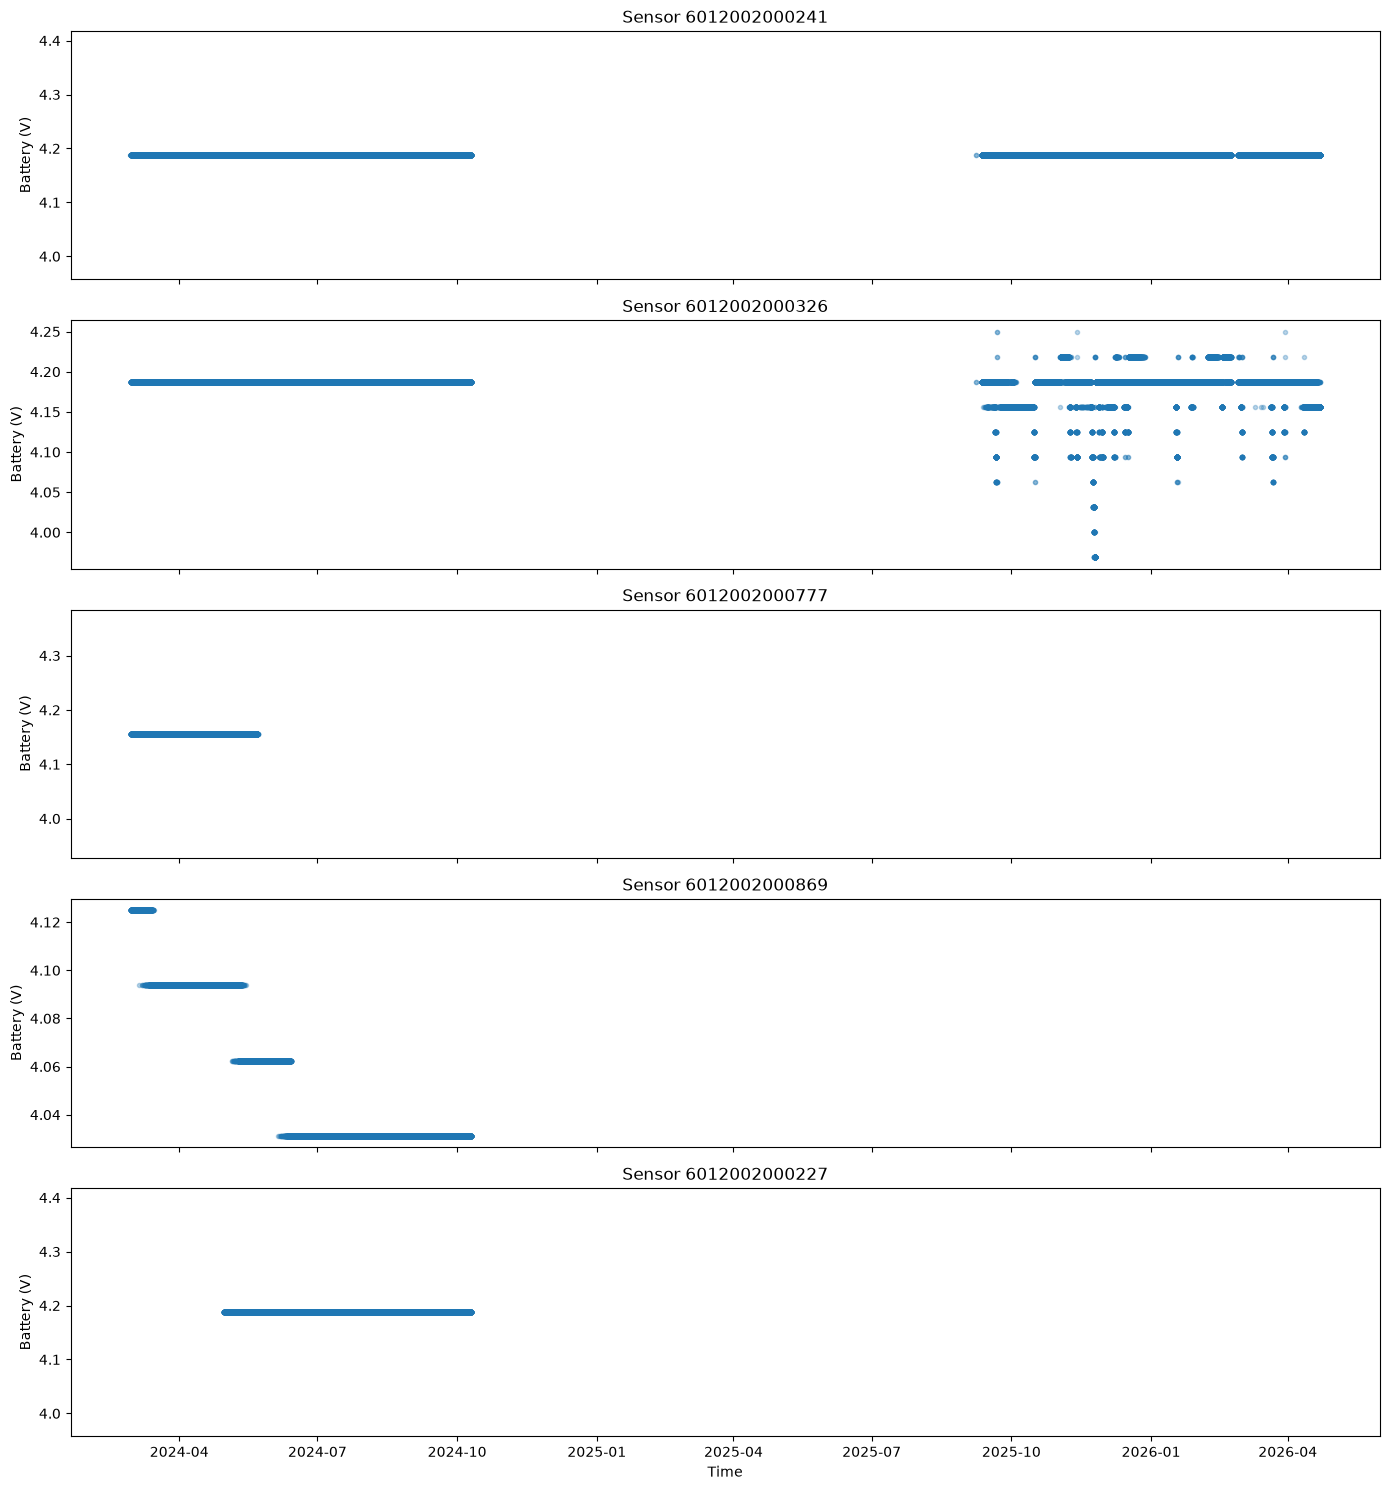

In [92]:
all_sensors = df_env_with_dupes['sensorid'].unique()
fig, axes = plt.subplots(len(all_sensors), 1, figsize=(14, 3 * len(all_sensors)), sharex=True)

for ax, sid in zip(axes, all_sensors):
    s = df_env_with_dupes[df_env_with_dupes['sensorid'] == sid].sort_values('timestamp')
    ax.plot(s['timestamp'], s['Battery'], marker='.', linestyle='none', alpha=0.3)
    ax.set_title(f'Sensor {sid}')
    ax.set_ylabel('Battery (V)')

axes[-1].set_xlabel('Time')
plt.tight_layout()
plt.show()

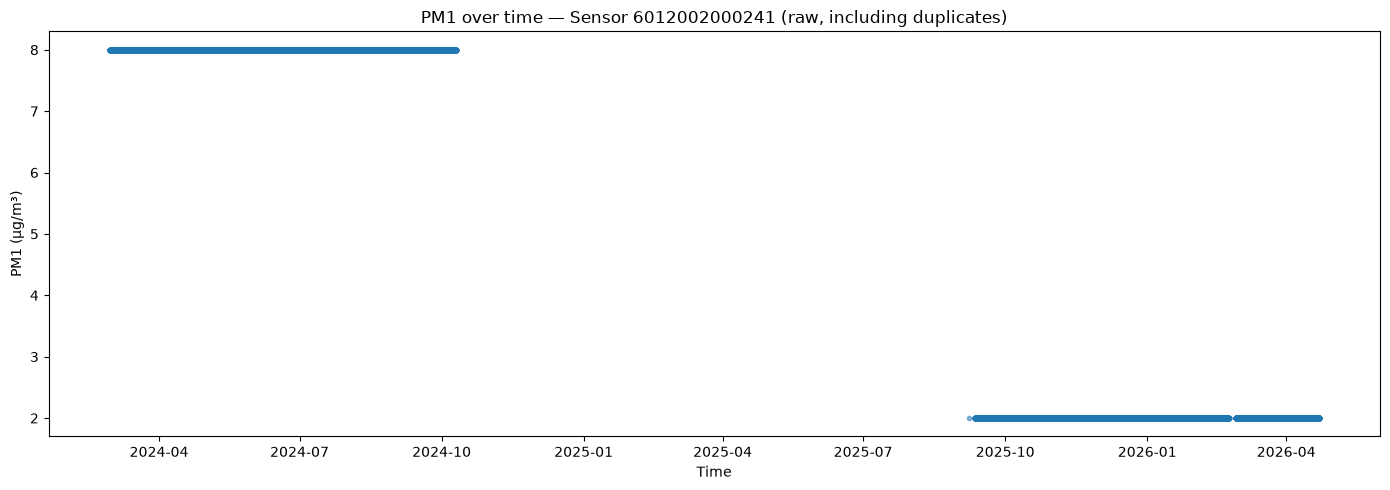

In [93]:
plt.figure(figsize=(14, 5))
plt.plot(audit_raw['timestamp'], audit_raw['Particulate matter 1'], marker='.', linestyle='none', alpha=0.3)
plt.xlabel('Time')
plt.ylabel('PM1 (µg/m³)')
plt.title(f'PM1 over time — Sensor {AUDIT_SENSOR} (raw, including duplicates)')
plt.tight_layout()
plt.show()

### 3.3 De-duplication

In [94]:
df_env = deduplicate(df_env_with_dupes)
print(f"Before: {df_env_with_dupes.shape}  After: {df_env.shape}")

Before: (179447, 14)  After: (42843, 14)


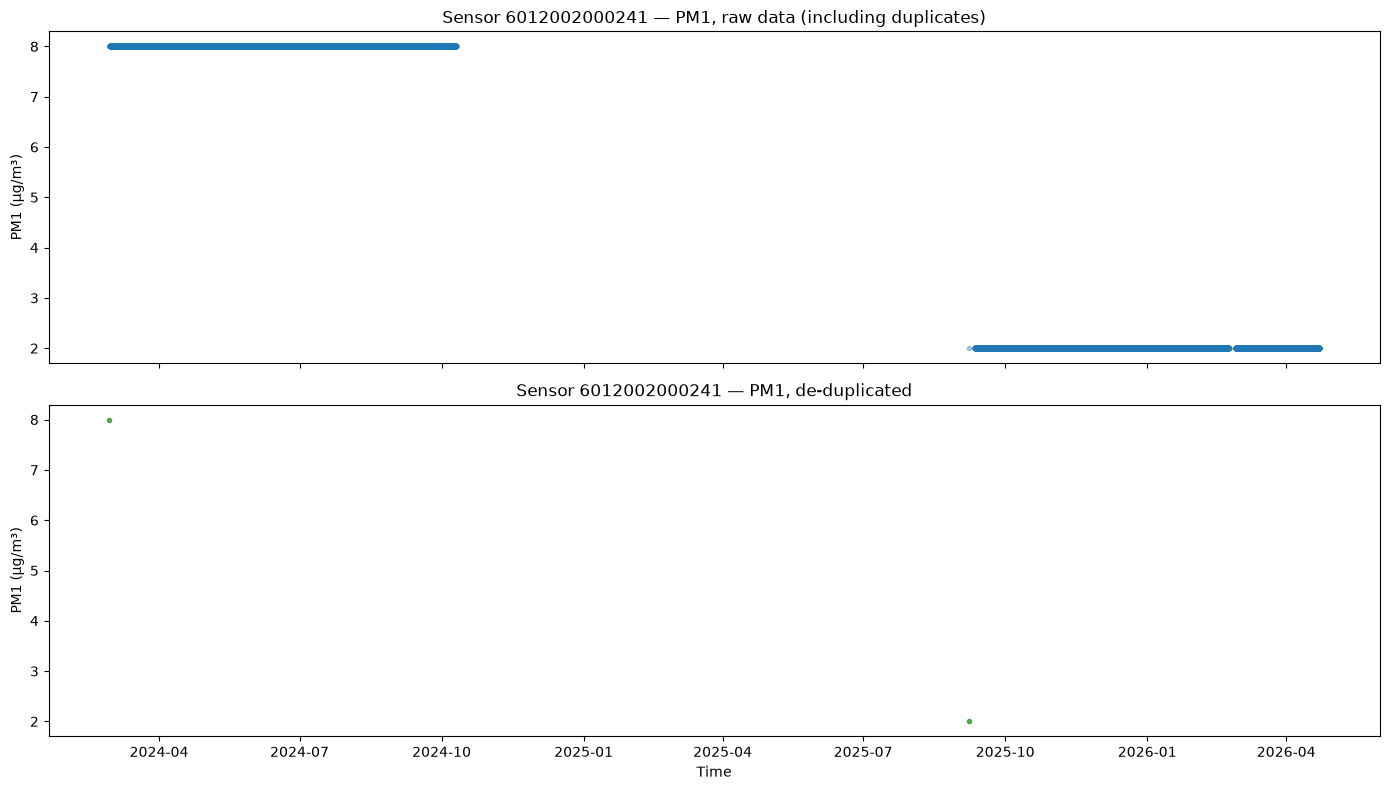

Std within one duplicate group: 0.0
Std across the 2 distinct readings left for this sensor: 4.242640687119285


In [95]:
# PM1 for the audit sensor, before vs after de-duplication
clean_audit = df_env[df_env['sensorid'] == AUDIT_SENSOR].sort_values('timestamp')

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
axes[0].plot(audit_raw['timestamp'], audit_raw['Particulate matter 1'], marker='.', linestyle='none', alpha=0.2)
axes[0].set_title(f'Sensor {AUDIT_SENSOR} — PM1, raw data (including duplicates)')
axes[0].set_ylabel('PM1 (µg/m³)')

axes[1].plot(clean_audit['timestamp'], clean_audit['Particulate matter 1'], marker='.', linestyle='none',
             alpha=0.6, color='green')
axes[1].set_title(f'Sensor {AUDIT_SENSOR} — PM1, de-duplicated')
axes[1].set_ylabel('PM1 (µg/m³)')
axes[1].set_xlabel('Time')
plt.tight_layout()
plt.show()

# Spread inside one duplicate group (should be zero) vs across the distinct readings that remain
print(f"Std within one duplicate group: {group_data['Particulate matter 1'].std()}")
print(f"Std across the {len(clean_audit)} distinct readings left for this sensor: "
      f"{clean_audit['Particulate matter 1'].std()}")

### 3.4 Per-sensor reliability summary

In [96]:
summary_rows = []
for sid in df_env_with_dupes['sensorid'].unique():
    s = df_env_with_dupes[df_env_with_dupes['sensorid'] == sid]
    total_rows = len(s)
    distinct_readings = s.drop_duplicates(subset=['sensorid', 'device_time']).shape[0]
    summary_rows.append({
        'sensorid': sid,
        'total_rows': total_rows,
        'distinct_readings': distinct_readings,
        'pct_real_data': round(distinct_readings / total_rows * 100, 1),
        'unique_co2_values': s['Carbon dioxide'].nunique(),
        'unique_pm1_values': s['Particulate matter 1'].nunique(),
    })

reliability_summary = pd.DataFrame(summary_rows).sort_values('pct_real_data')
print(reliability_summary)

        sensorid  total_rows  distinct_readings  pct_real_data  \
0  6012002000241       58908                  2            0.0   
2  6012002000777       10926                  1            0.0   
4  6012002000227       21363                  1            0.0   
3  6012002000869       29341              13800           47.0   
1  6012002000326       58909              29039           49.3   

   unique_co2_values  unique_pm1_values  
0                  2                  2  
2                  1                  1  
4                  1                  1  
3                222                 68  
1                245                 21  


## 4. Cleaning

In [97]:
# 4.1 Missing values
modelling_rows = df_env['sensorid'].isin(sensor_names)

print("Missing values per column (%), all sensors after de-duplication:")
print((df_env.isna().mean() * 100).round(1))
print(f"\nFormaldehyde missing, modelling sensors only: "
      f"{df_env.loc[modelling_rows, 'Formaldehyde'].isna().mean() * 100:.1f}%")

# Formaldehyde is mostly missing: drop the column rather than impute it
df_env = df_env.drop(columns=['Formaldehyde'])

# Rows missing any PM reading are a small share: drop them
pm_missing = df_env[PM_RAW].isna().any(axis=1)
print(f"Rows missing PM data: {pm_missing.sum()} total, "
      f"{(pm_missing & modelling_rows).sum()} among the modelling sensors")
df_env = df_env.dropna(subset=PM_RAW)
print(df_env.shape)

Missing values per column (%), all sensors after de-duplication:
sensorid                             0.0
timestamp                            0.0
device_time                          0.0
Battery                              0.0
Carbon dioxide                       0.0
Humidity                             0.0
Formaldehyde                        67.8
Pressure                             0.0
Temperature                          0.0
Light Volatile Organic Compounds     0.0
Particulate matter 1                 4.0
Particulate matter 4                 4.0
Particulate matter 2.5               4.0
Particulate matter 10                4.0
dtype: float64

Formaldehyde missing, modelling sensors only: 67.8%
Rows missing PM data: 1693 total, 1693 among the modelling sensors
(41150, 13)


In [98]:
# 4.2 Keep only the two reliable sensors
df_model = df_env[df_env['sensorid'].isin(sensor_names)].copy()
print(df_model.shape)
print(df_model['sensorid'].value_counts())

(41146, 13)
sensorid
6012002000326    27346
6012002000869    13800
Name: count, dtype: int64


In [99]:
# 4.3 Clean, consistent column names
df_model = df_model.rename(columns=COLUMN_RENAMES)
df_model.head()

,sensorid,timestamp,device_time,Battery,co2,humidity,pressure,temperature,voc,pm1,pm4,pm2_5,pm10
1,6012002000326,2024-02-29 06:09:12.444245+00:00,1702270857,4.1875,525,68,1012,23.8,7.0,6.0,6.0,6.0,6.0
3,6012002000869,2024-02-29 06:11:11.348578+00:00,1709186696,4.1250,465,56,1010,24.3,0.0,2.0,2.0,2.0,2.0
4,6012002000869,2024-02-29 06:24:31.400806+00:00,1709187297,4.1250,445,56,1010,24.0,0.0,2.0,5.0,4.0,5.0
5,6012002000869,2024-02-29 06:38:05.661335+00:00,1709188497,4.1250,471,56,1010,23.8,0.0,1.0,2.0,2.0,2.0
6,6012002000869,2024-02-29 06:51:24.418554+00:00,1709189097,4.1250,457,56,1010,23.8,0.0,1.0,2.0,2.0,3.0


In [100]:
# 4.4 Local-time hour of day (timestamps are UTC; occupancy follows Melbourne time)
df_model['local_time'] = df_model['timestamp'].dt.tz_convert(LOCAL_TZ)
df_model['hour'] = df_model['local_time'].dt.hour

print(df_model.shape)
print(df_model.isna().sum())

(41146, 15)
sensorid       0
timestamp      0
device_time    0
Battery        0
co2            0
humidity       0
pressure       0
temperature    0
voc            0
pm1            0
pm4            0
pm2_5          0
pm10           0
local_time     0
hour           0
dtype: int64


## 5. Domain check

In [101]:
numeric_cols = [TARGET] + [f for f in features if f != 'hour']

print(df_model[numeric_cols].describe().T)

               count         mean         std    min     25%     50%     75%  \
co2          41146.0   451.980897   34.664744  400.0   431.0   443.0   462.0   
humidity     41146.0    50.766028   10.172557   17.0    43.0    50.0    58.0   
pressure     41146.0  1011.814174    7.331667  988.0  1007.0  1012.0  1017.0   
temperature  41146.0    21.713807    3.385510   11.8    19.3    22.3    23.8   
voc          41146.0    12.397730  129.797416    0.0     0.0     0.0     0.0   
pm1          41146.0     1.206193    4.334368    0.0     0.0     0.0     1.0   
pm4          41146.0     1.916347    5.507264    0.0     0.0     0.0     2.0   
pm2_5        41146.0     1.620619    5.031948    0.0     0.0     0.0     2.0   
pm10         41146.0     1.978200    5.629436    0.0     0.0     0.0     2.0   

                max  
co2          1387.0  
humidity       84.0  
pressure     1028.0  
temperature    37.5  
voc          8051.0  
pm1            73.0  
pm4           163.0  
pm2_5         105.0  
p

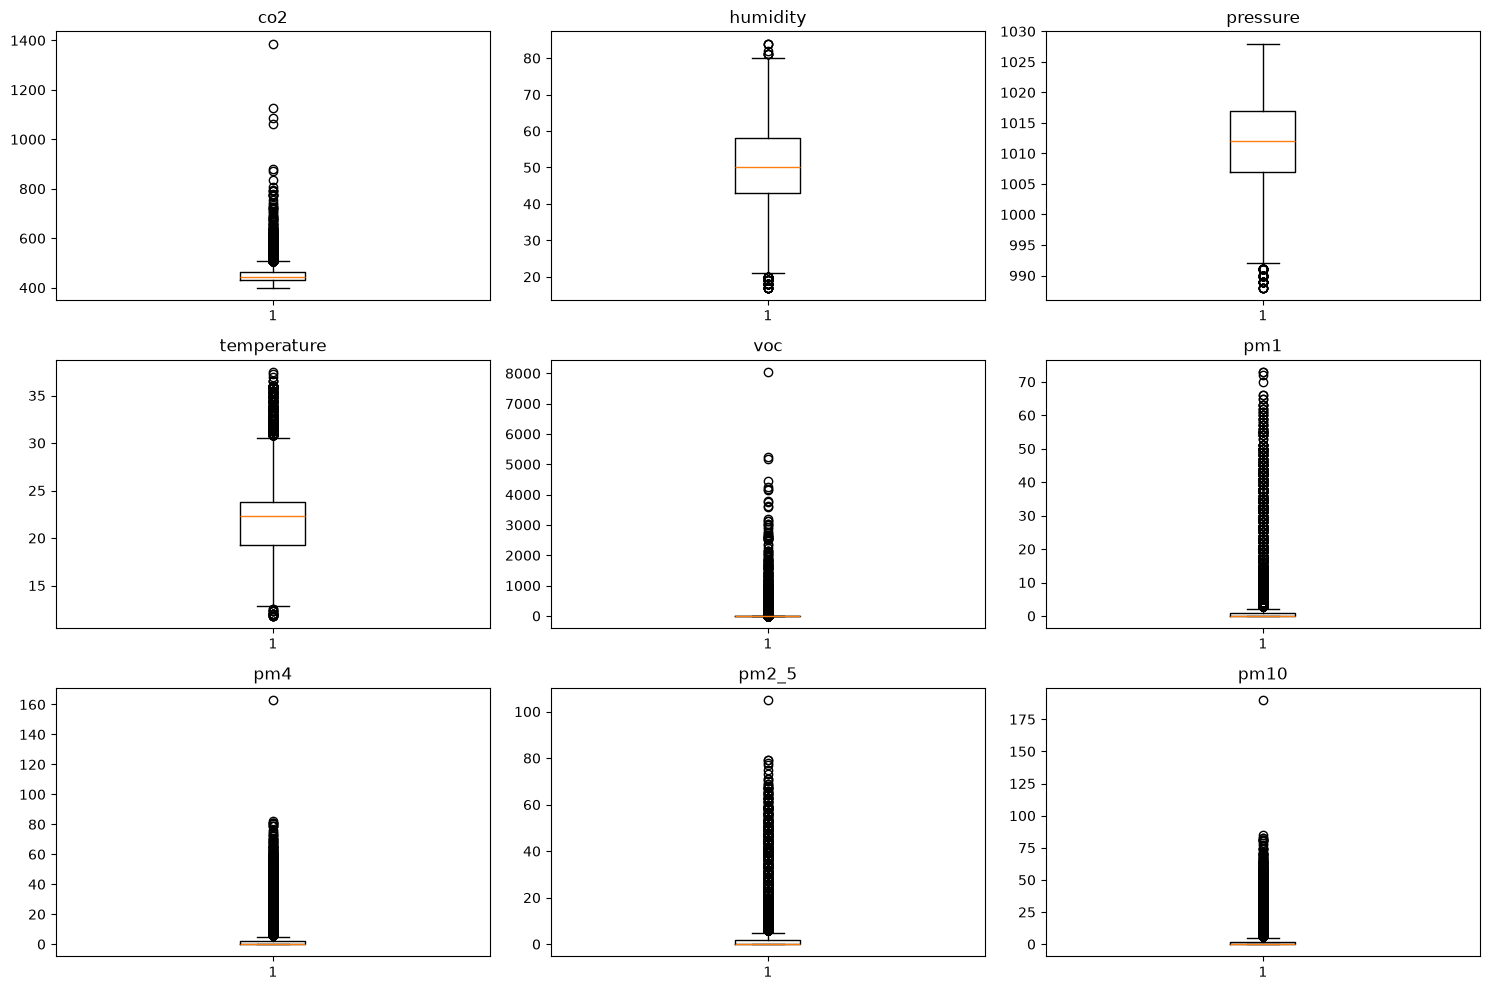

In [102]:
fig, axes = plt.subplots(3, 3, figsize=(15, 10))
axes = axes.flatten()

for i, col in enumerate(numeric_cols):
    axes[i].boxplot(df_model[col].dropna())
    axes[i].set_title(col)

plt.tight_layout()
plt.show()

### 5.1 Temperature note

In [103]:
unknown_room_df = df_model[df_model['sensorid'] == UNKNOWN_ROOM].sort_values('timestamp')

hot_readings = unknown_room_df[unknown_room_df['temperature'] > 32].sort_values('temperature', ascending=False)
print(hot_readings[['timestamp', 'temperature', 'humidity', 'pressure', 'co2']].head(20))

                             timestamp  temperature  humidity  pressure  co2
29619 2026-01-09 05:36:04.583513+00:00         37.5        18       992  418
29620 2026-01-09 06:07:56.224677+00:00         37.3        18       992  413
29618 2026-01-09 05:14:46.644722+00:00         37.0        19       993  423
29616 2026-01-09 04:21:40.477567+00:00         36.5        20       993  420
29621 2026-01-09 06:39:48.991112+00:00         36.5        26       994  411
29617 2026-01-09 04:32:17.676535+00:00         36.5        20       993  420
29359 2026-01-07 06:04:41.069080+00:00         36.0        20      1004  426
29361 2026-01-07 06:25:59.078083+00:00         36.0        19      1004  417
29362 2026-01-07 06:36:36.562609+00:00         36.0        18      1004  427
29365 2026-01-07 07:08:28.520726+00:00         36.0        18      1004  413
29366 2026-01-07 07:19:05.911130+00:00         36.0        18      1004  423
29364 2026-01-07 06:57:51.234623+00:00         36.0        18      1004  427

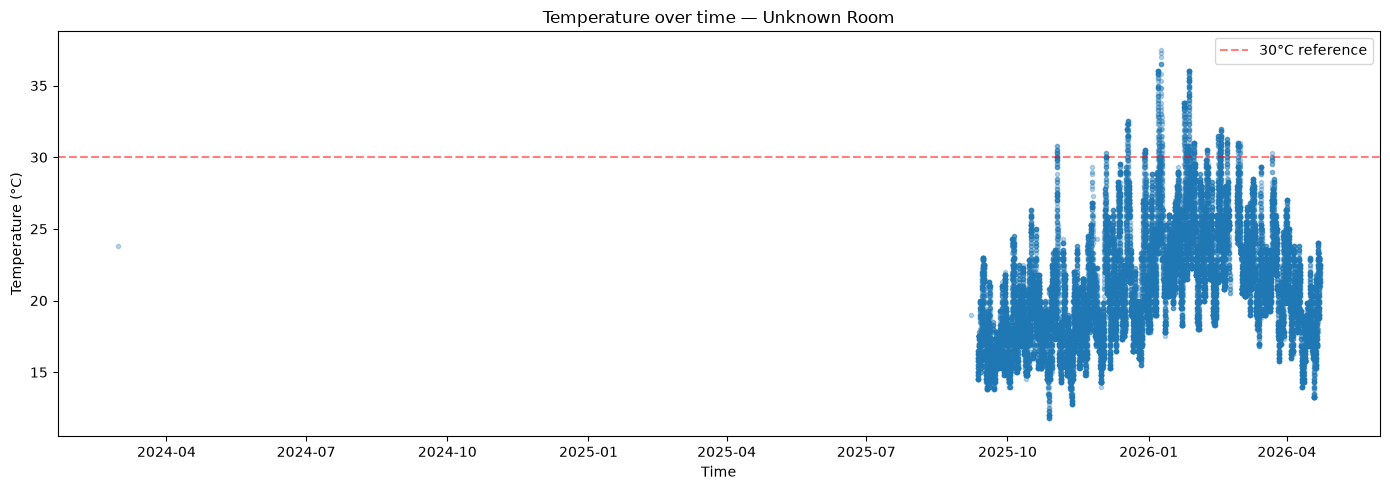

In [104]:
plt.figure(figsize=(14, 5))
plt.plot(unknown_room_df['timestamp'], unknown_room_df['temperature'], marker='.', linestyle='none', alpha=0.3)
plt.axhline(30, color='red', linestyle='--', alpha=0.5, label='30°C reference')
plt.xlabel('Time')
plt.ylabel('Temperature (°C)')
plt.title('Temperature over time — Unknown Room')
plt.legend()
plt.tight_layout()
plt.show()

### 5.2 VOC note

In [105]:
# Largest VOC readings and what else was happening at those moments
top_voc = df_model.sort_values('voc', ascending=False).head(20)
print(top_voc[['timestamp', 'sensorid', 'voc', 'co2', 'temperature', 'humidity', 'pm1', 'pm2_5']])

                             timestamp       sensorid     voc  co2  \
42009 2026-04-16 09:25:30.913293+00:00  6012002000326  8051.0  486   
39177 2026-03-26 10:45:17.857454+00:00  6012002000326  5246.0  471   
42158 2026-04-17 11:49:28.730583+00:00  6012002000326  5168.0  495   
42557 2026-04-20 10:40:42.069894+00:00  6012002000326  4436.0  498   
40121 2026-04-02 10:18:30.836611+00:00  6012002000326  4267.0  453   
35919 2026-03-02 08:49:03.240673+00:00  6012002000326  4183.0  470   
42695 2026-04-21 11:18:04.399715+00:00  6012002000326  4146.0  494   
41738 2026-04-14 09:11:26.702843+00:00  6012002000326  3798.0  474   
32234 2026-01-29 10:41:32.479835+00:00  6012002000326  3761.0  526   
38762 2026-03-23 09:01:40.640910+00:00  6012002000326  3614.0  490   
30562 2026-01-17 02:04:51.876815+00:00  6012002000326  3608.0  484   
37004 2026-03-10 09:28:18.400911+00:00  6012002000326  3210.0  442   
30874 2026-01-19 09:23:42.797928+00:00  6012002000326  3124.0  444   
22900 2025-11-18 10:

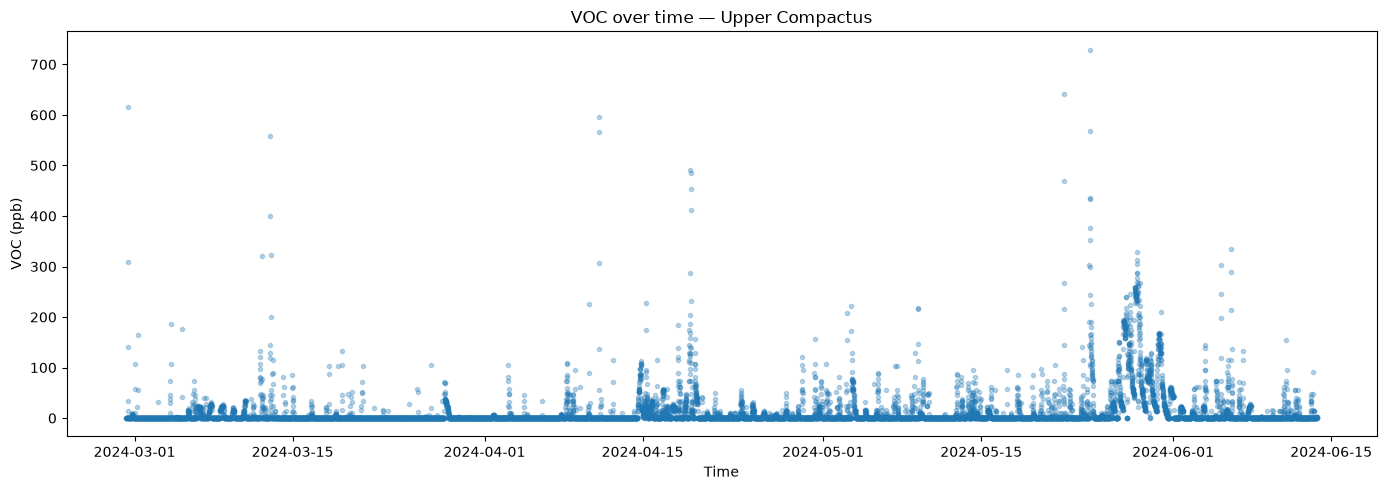

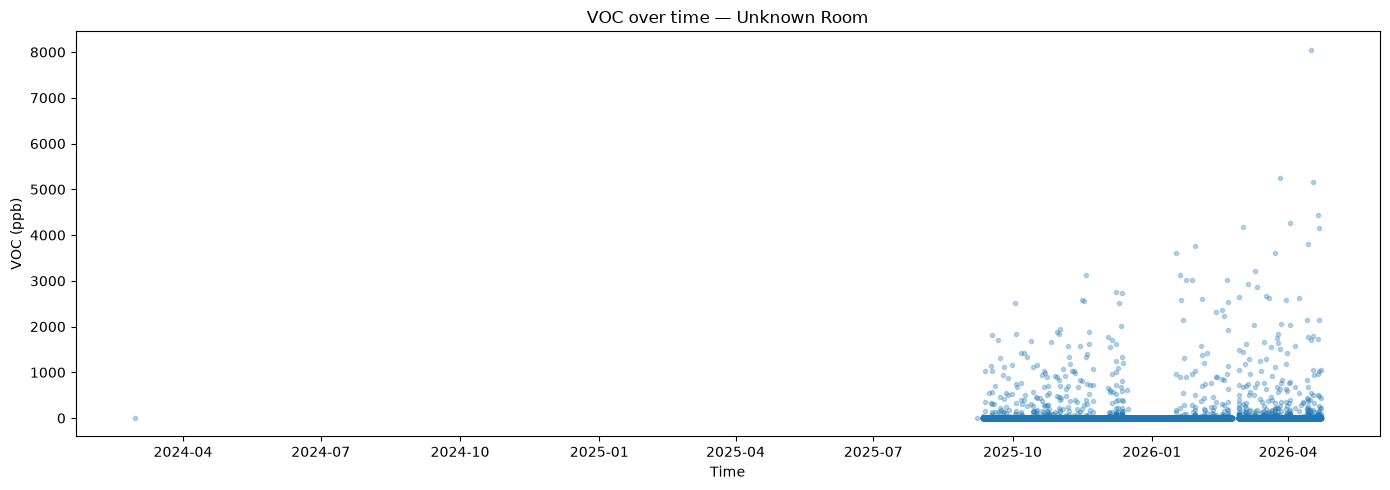

In [106]:
# VOC over time per sensor: isolated spikes or clustered events?
for sid in sensor_names:
    s = df_model[df_model['sensorid'] == sid].sort_values('timestamp')

    plt.figure(figsize=(14, 5))
    plt.plot(s['timestamp'], s['voc'], marker='.', linestyle='none', alpha=0.3)
    plt.xlabel('Time')
    plt.ylabel('VOC (ppb)')
    plt.title(f'VOC over time — {sensor_names[sid]}')
    plt.tight_layout()
    plt.show()

In [107]:
# Local hour of the large VOC spikes in the Unknown Room
voc_spikes = df_model[(df_model['sensorid'] == UNKNOWN_ROOM) & (df_model['voc'] > 1000)]
print(voc_spikes['hour'].value_counts().sort_index())

hour
0      1
13     1
14     3
15     1
16     2
17     1
18     3
19    17
20    21
21    50
22    17
23     1
Name: count, dtype: int64


## 6. Exploratory analysis

co2            1.000000
pressure       0.406001
pm10           0.173754
pm4            0.171545
pm2_5          0.154721
pm1            0.127712
temperature    0.062153
voc            0.050396
humidity      -0.058503
Name: co2, dtype: float64


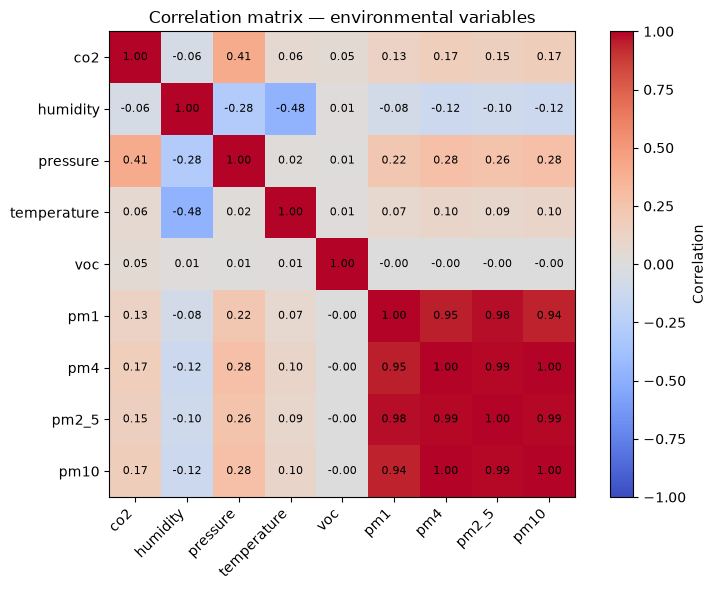

In [108]:
# Pooled correlation matrix
corr_matrix = df_model[numeric_cols].corr()

# The CO2 row, strongest first
print(corr_matrix[TARGET].sort_values(ascending=False))

plt.figure(figsize=(8, 6))
plt.imshow(corr_matrix, cmap='coolwarm', vmin=-1, vmax=1)
plt.colorbar(label='Correlation')
plt.xticks(range(len(numeric_cols)), numeric_cols, rotation=45, ha='right')
plt.yticks(range(len(numeric_cols)), numeric_cols)
for i in range(len(numeric_cols)):
    for j in range(len(numeric_cols)):
        plt.text(j, i, f'{corr_matrix.iloc[i, j]:.2f}', ha='center', va='center', fontsize=8)
plt.title('Correlation matrix — environmental variables')
plt.tight_layout()
plt.show()

In [109]:
# Per-sensor correlation with CO2 (including hour of day)
for sid in sensor_names:
    s = df_model[df_model['sensorid'] == sid]
    print(f"\n{sensor_names[sid]} (sensor {sid}):")
    print(s[[TARGET] + features].corr()[TARGET].sort_values(ascending=False))


Upper Compactus (sensor 6012002000869):
co2            1.000000
pressure       0.304985
temperature    0.170572
hour           0.135035
voc            0.042331
humidity       0.010713
pm1           -0.075531
pm2_5         -0.078499
pm4           -0.079480
pm10          -0.079563
Name: co2, dtype: float64

Unknown Room (sensor 6012002000326):
co2            1.000000
humidity       0.242624
pressure       0.130907
voc            0.085323
pm2_5          0.034721
pm4            0.033923
pm10           0.033725
pm1            0.032892
temperature   -0.160069
hour          -0.218133
Name: co2, dtype: float64


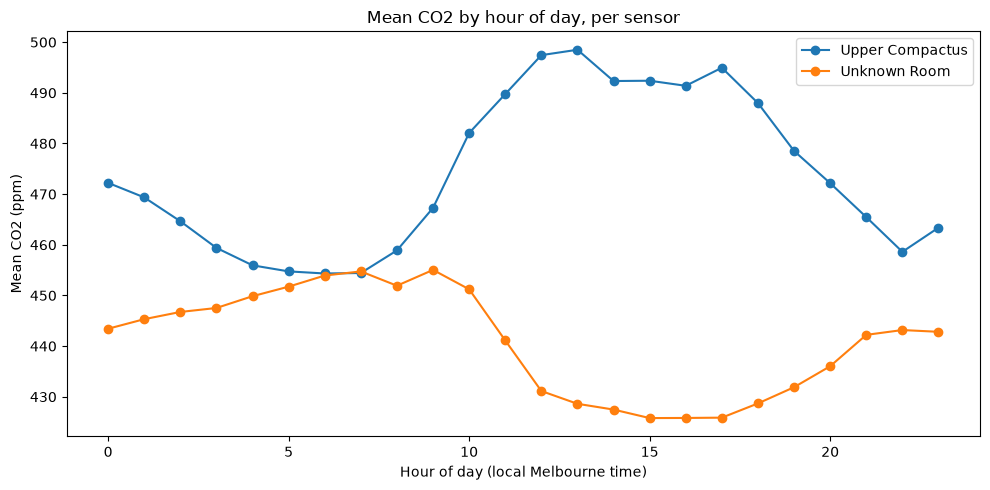

In [110]:
# Mean CO2 by local hour of day, per sensor
plt.figure(figsize=(10, 5))
for sid in sensor_names:
    hourly = df_model[df_model['sensorid'] == sid].groupby('hour')[TARGET].mean()
    plt.plot(hourly.index, hourly.values, marker='o', label=sensor_names[sid])

plt.xlabel('Hour of day (local Melbourne time)')
plt.ylabel('Mean CO2 (ppm)')
plt.title('Mean CO2 by hour of day, per sensor')
plt.legend()
plt.tight_layout()
plt.show()

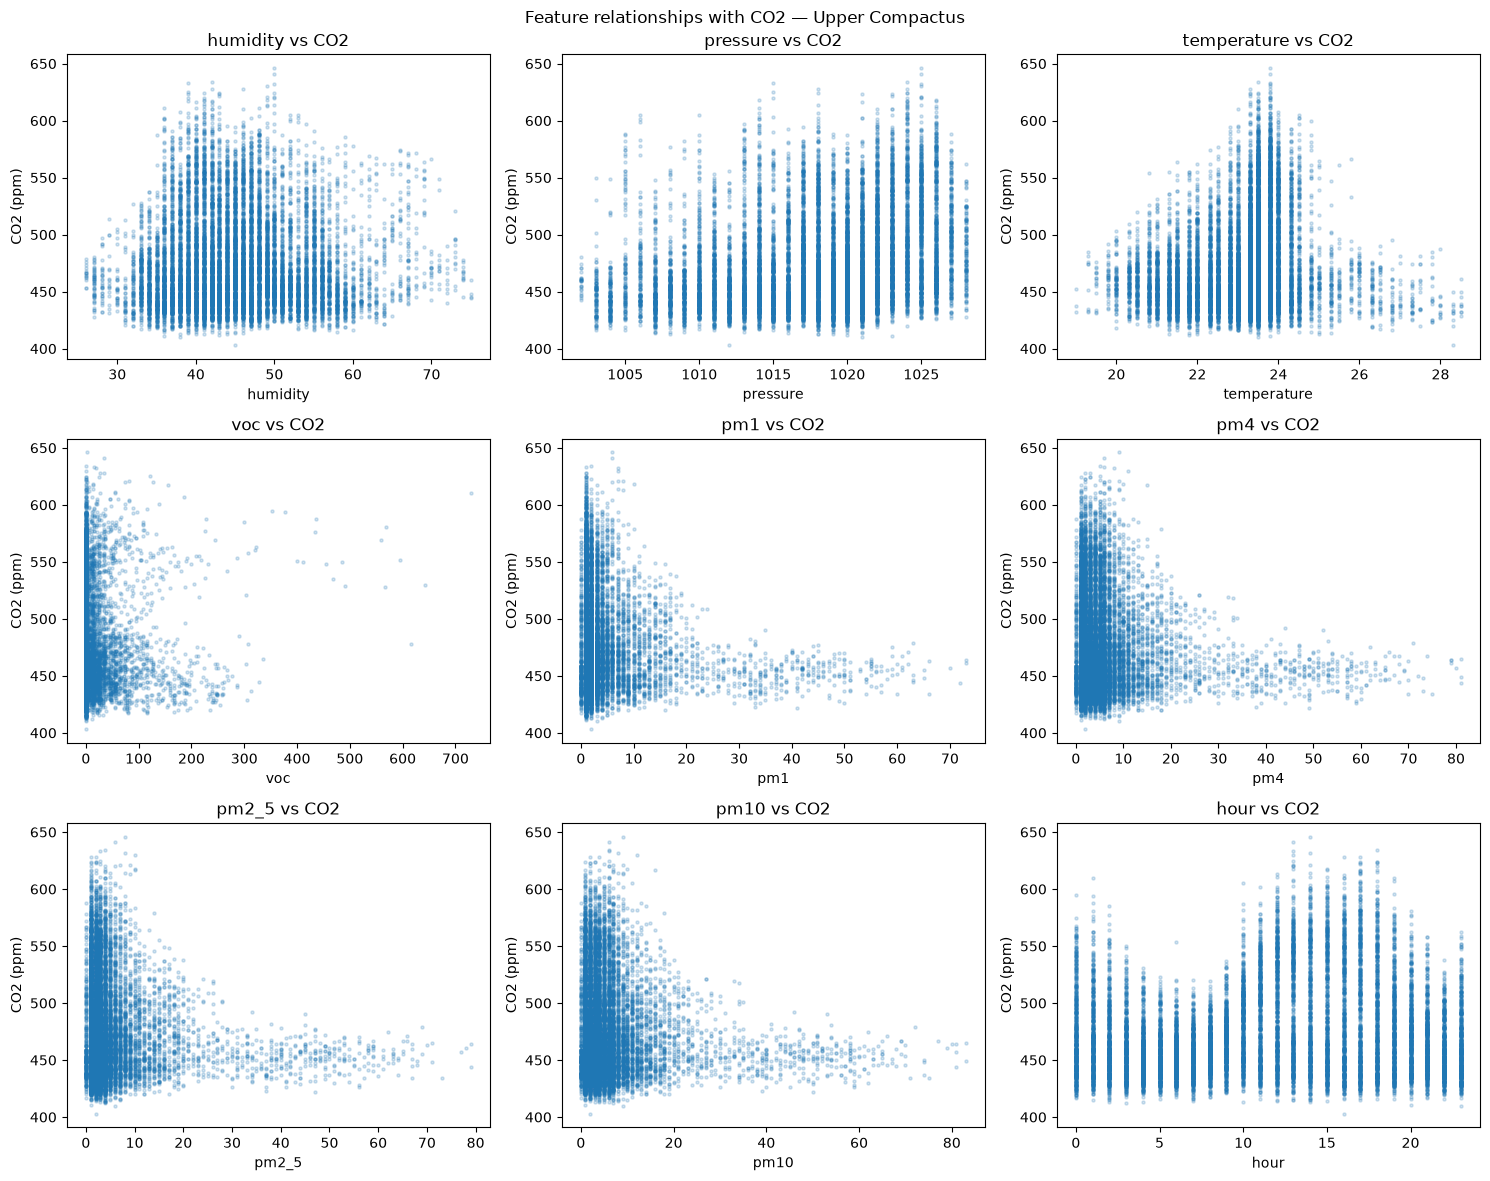

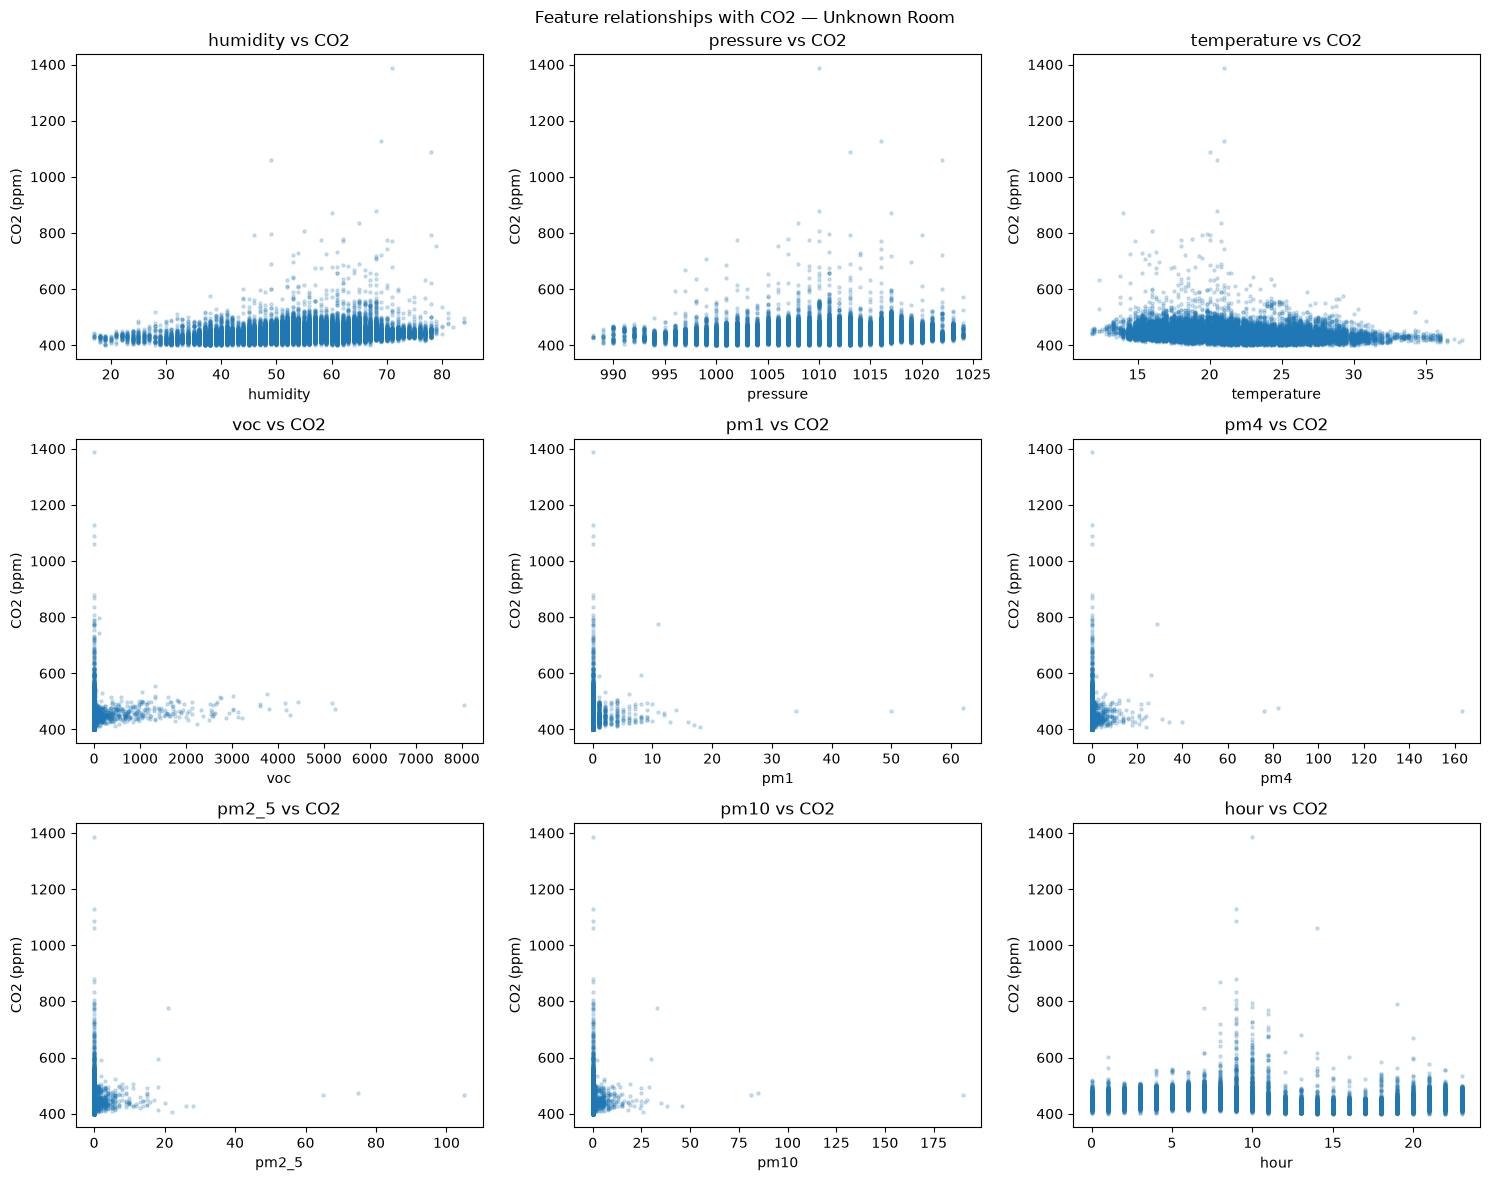

In [111]:
# Each feature against CO2, per sensor
for sid in sensor_names:
    s = df_model[df_model['sensorid'] == sid]

    fig, axes = plt.subplots(3, 3, figsize=(15, 12))
    axes = axes.flatten()
    for i, feat in enumerate(features):
        axes[i].scatter(s[feat], s[TARGET], alpha=0.2, s=5)
        axes[i].set_xlabel(feat)
        axes[i].set_ylabel('CO2 (ppm)')
        axes[i].set_title(f'{feat} vs CO2')

    fig.suptitle(f'Feature relationships with CO2 — {sensor_names[sid]}')
    plt.tight_layout()
    plt.show()

## 7. Models

In [112]:
# ---- shared helpers for Sections 7 to 9 ----

def get_split(sid):
    '''Chronological train/test split for one sensor (first TRAIN_FRAC for training).'''
    sub = df_model[df_model['sensorid'] == sid].sort_values('timestamp')
    split_idx = int(len(sub) * TRAIN_FRAC)
    return sub.iloc[:split_idx], sub.iloc[split_idx:]


def prepare(sid):
    '''Split one sensor's data and standardise the inputs (scaler fitted on training data only).'''
    train, test = get_split(sid)
    scaler = StandardScaler()
    return {
        'train': train, 'test': test,
        'X_train': scaler.fit_transform(train[features]),
        'X_test': scaler.transform(test[features]),
        'y_train': train[TARGET].to_numpy(),
        'y_test': test[TARGET].to_numpy(),
        'scaler': scaler,
    }


def score(y_true, y_pred):
    '''RMSE (ppm), MAE (ppm) and R^2 for one set of predictions.'''
    return {
        'rmse': root_mean_squared_error(y_true, y_pred),
        'mae': mean_absolute_error(y_true, y_pred),
        'r2': r2_score(y_true, y_pred),
    }


data = {sid: prepare(sid) for sid in sensor_names}
results = {}   # (sensorid, model name) -> metrics incl. fit time
preds = {}     # (sensorid, model name) -> test-set predictions
models = {}  # (sensorid, model name) -> fitted model 



def fit_and_score(sid, name, model):
    '''Fit a model on one sensor's training data, time the fit, score it on the test period and store the results.'''
    d = data[sid]
    t0 = time.perf_counter()
    model.fit(d['X_train'], d['y_train'])
    fit_s = time.perf_counter() - t0
    pred = model.predict(d['X_test'])
    results[(sid, name)] = {**score(d['y_test'], pred), 'fit_s': fit_s}
    preds[(sid, name)] = pred
    models[(sid,name)] = model
    return results[(sid, name)]


def plot_actual_vs_pred(sid, name, suptitle=None):
    '''Actual-vs-predicted scatter and actual/predicted time series for the test period.'''
    d = data[sid]
    y, pred = d['y_test'], preds[(sid, name)]
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))

    axes[0].scatter(y, pred, alpha=0.3, s=10)
    lims = [min(y.min(), pred.min()), max(y.max(), pred.max())]
    axes[0].plot(lims, lims, color='red', linestyle='--', label='Perfect prediction')
    axes[0].set_xlabel('Actual CO2 (ppm)')
    axes[0].set_ylabel('Predicted CO2 (ppm)')
    axes[0].set_title('Actual vs Predicted')
    axes[0].legend()

    axes[1].plot(d['test']['timestamp'], y, label='Actual', alpha=0.6, linewidth=1)
    axes[1].plot(d['test']['timestamp'], pred, label='Predicted', alpha=0.6, linewidth=1)
    axes[1].set_xlabel('Time')
    axes[1].set_ylabel('CO2 (ppm)')
    axes[1].set_title('Actual vs Predicted over time (test period)')
    axes[1].legend()
    axes[1].tick_params(axis='x', rotation=45)

    fig.suptitle(suptitle or f'{name} — {sensor_names[sid]}')
    plt.tight_layout()
    plt.show()

### 7.1 computational solution (baseline): SVR with starting parameters

Upper Compactus: SVR RMSE=32.26 ppm, MAE=26.37 ppm, R²=-1.132


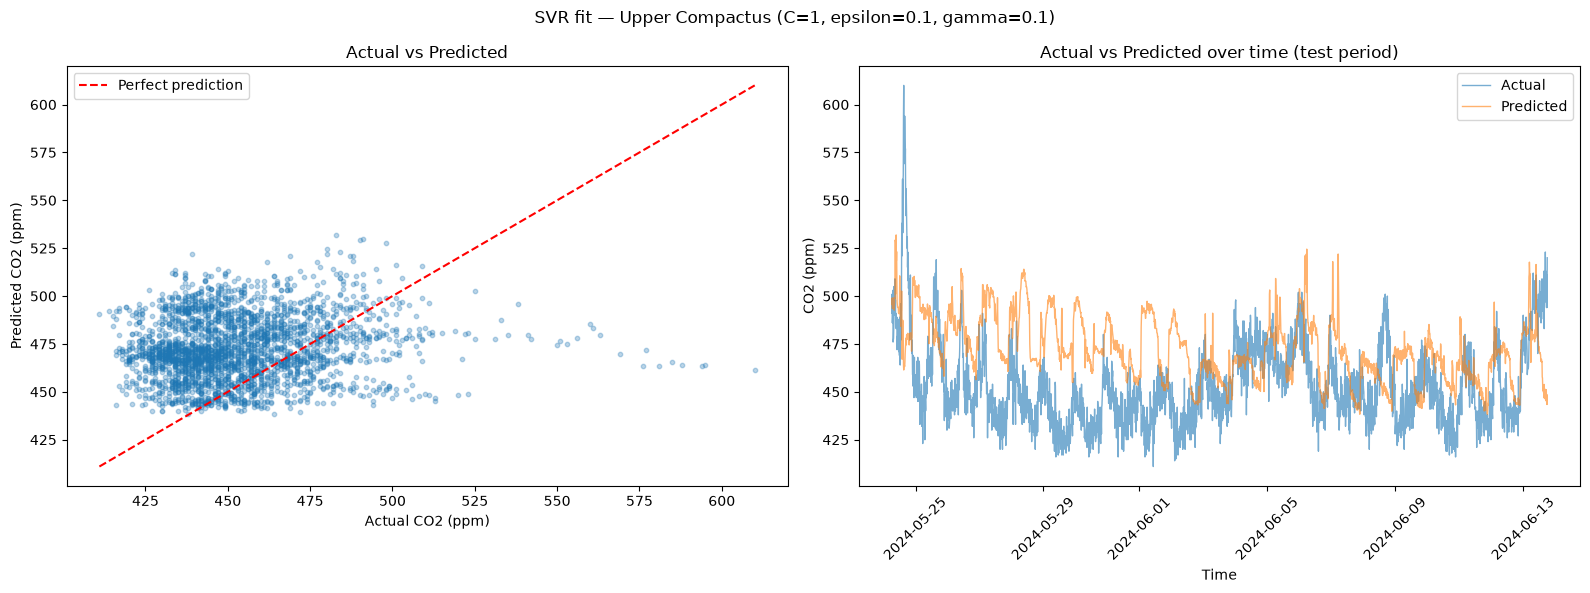

Unknown Room: SVR RMSE=28.81 ppm, MAE=15.37 ppm, R²=0.085


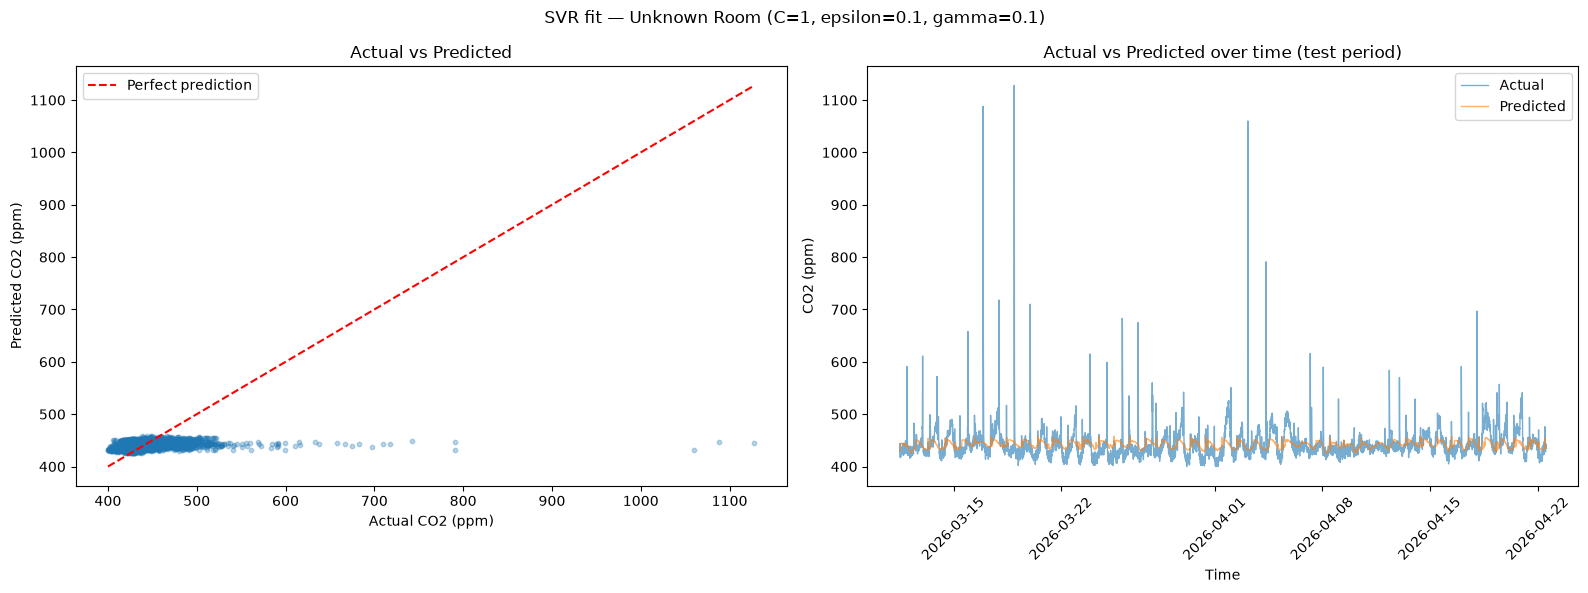

In [113]:
for sid in sensor_names:
    m = fit_and_score(sid, 'SVR (baseline)', SVR(kernel='rbf', **baseline_params))
    print(f"{sensor_names[sid]}: SVR RMSE={m['rmse']:.2f} ppm, MAE={m['mae']:.2f} ppm, R²={m['r2']:.3f}")
    plot_actual_vs_pred(sid, 'SVR (baseline)',
                        suptitle=f'SVR fit — {sensor_names[sid]} (C=1, epsilon=0.1, gamma=0.1)')

### 7.2 alternative solution: Linear regression

In [114]:
for sid in sensor_names:
    m = fit_and_score(sid, 'Linear Regression', LinearRegression())
    print(f"{sensor_names[sid]} (sensor {sid}):")
    print(f"  Linear Regression — RMSE={m['rmse']:.2f} ppm, MAE={m['mae']:.2f} ppm, R²={m['r2']:.3f}")

Upper Compactus (sensor 6012002000869):
  Linear Regression — RMSE=34.22 ppm, MAE=27.54 ppm, R²=-1.400
Unknown Room (sensor 6012002000326):
  Linear Regression — RMSE=29.58 ppm, MAE=18.11 ppm, R²=0.035


In [115]:
# Pooled check: train one model on both sensors' training data, score it on each sensor's own test period
train_p = pd.concat([data[sid]['train'] for sid in sensor_names])
scaler_p = StandardScaler().fit(train_p[features])
lr_pooled = LinearRegression().fit(scaler_p.transform(train_p[features]), train_p[TARGET])

for sid in sensor_names:
    d = data[sid]
    pooled_m = score(d['y_test'], lr_pooled.predict(scaler_p.transform(d['test'][features])))
    own_m = results[(sid, 'Linear Regression')]
    print(f"{sensor_names[sid]}: pooled RMSE={pooled_m['rmse']:.2f} ppm (R²={pooled_m['r2']:.3f})  vs  "
          f"own-sensor RMSE={own_m['rmse']:.2f} ppm (R²={own_m['r2']:.3f})")

Upper Compactus: pooled RMSE=23.21 ppm (R²=-0.104)  vs  own-sensor RMSE=34.22 ppm (R²=-1.400)
Unknown Room: pooled RMSE=36.39 ppm (R²=-0.459)  vs  own-sensor RMSE=29.58 ppm (R²=0.035)


### 7.3 Optimisation: grid search over C and gamma

In [116]:
def svr_grid(sid, C_values, gamma_values, epsilon=0.1, label=''):
    '''Grid search SVR (C, gamma) for one sensor; plot a validation-RMSE heatmap.

    Returns
    -------
    dict
        Best 'C', 'gamma', its 'rmse' (ppm) and 'on_edge' (True if the best cell lies on the grid boundary).
    '''
    d = data[sid]
    rmse_grid = np.zeros((len(C_values), len(gamma_values)))
    for i, C in enumerate(C_values):
        for j, gamma in enumerate(gamma_values):
            pred = SVR(kernel='rbf', C=C, gamma=gamma, epsilon=epsilon).fit(d['X_train'], d['y_train']).predict(d['X_test'])
            rmse_grid[i, j] = root_mean_squared_error(d['y_test'], pred)

    bi, bj = np.unravel_index(np.argmin(rmse_grid), rmse_grid.shape)
    best = {'C': C_values[bi], 'gamma': gamma_values[bj], 'rmse': rmse_grid[bi, bj],
            'on_edge': bi in (0, len(C_values) - 1) or bj in (0, len(gamma_values) - 1)}

    print(f"{sensor_names[sid]} {label}: best C={best['C']:.4g}, best gamma={best['gamma']:.4g}, "
          f"RMSE={best['rmse']:.2f} ppm (epsilon={epsilon})")
    if best['on_edge']:
        print("  WARNING: best cell is on the edge of the grid - the optimum is not bracketed.")

    fig, ax = plt.subplots(figsize=(8, 6))
    im = ax.imshow(rmse_grid, cmap='viridis_r', aspect='auto')
    ax.set_xticks(range(len(gamma_values)))
    ax.set_xticklabels([f'{g:.3g}' for g in gamma_values])
    ax.set_yticks(range(len(C_values)))
    ax.set_yticklabels([f'{c:.3g}' for c in C_values])
    ax.set_xlabel('gamma')
    ax.set_ylabel('C')
    ax.set_title(f'Validation RMSE (ppm) — {sensor_names[sid]} {label}'.strip())
    for i in range(len(C_values)):
        for j in range(len(gamma_values)):
            ax.text(j, i, f'{rmse_grid[i, j]:.2f}', ha='center', va='center', color='white', fontsize=10)
    fig.colorbar(im, ax=ax, label='Validation RMSE (ppm)')
    plt.tight_layout()
    plt.show()
    return best

Unknown Room : best C=10, best gamma=0.1, RMSE=28.77 ppm (epsilon=0.1)


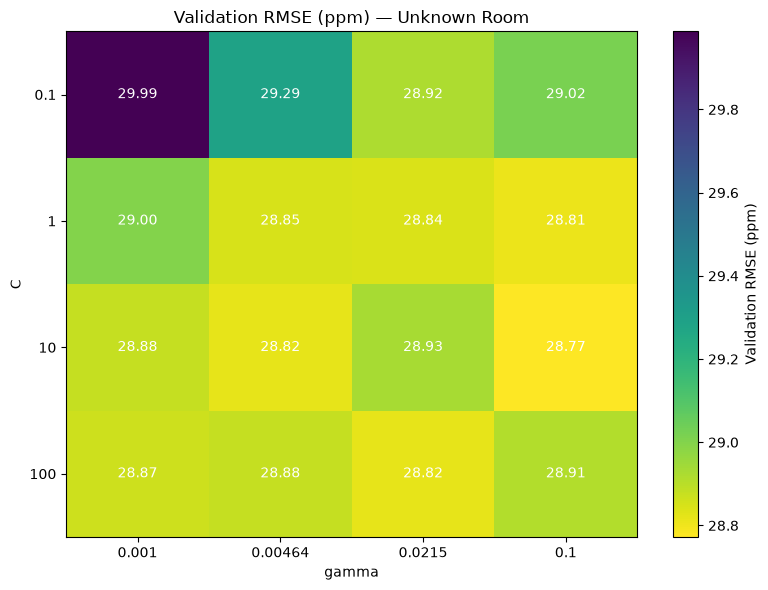

Upper Compactus : best C=0.01, best gamma=10, RMSE=26.48 ppm (epsilon=0.1)


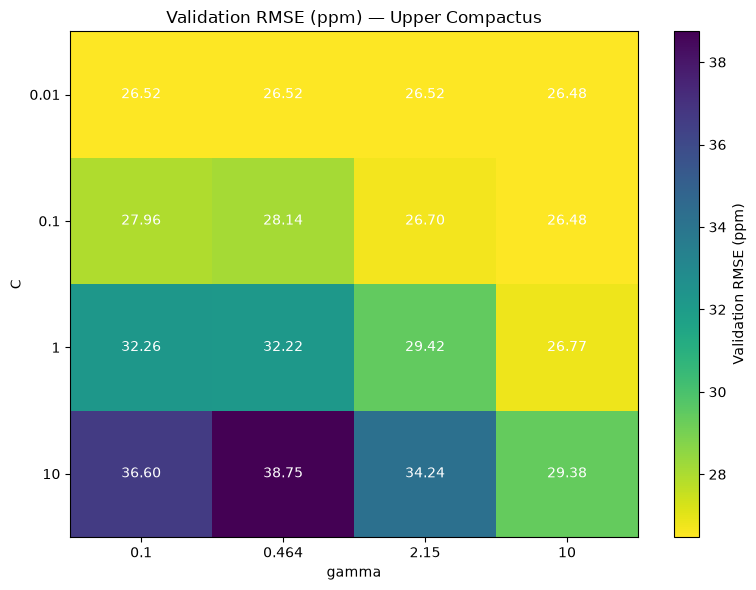

In [117]:
# Stage 1: a first grid per sensor (epsilon fixed at 0.1)
svr_grids = {
    UNKNOWN_ROOM:    {'C': np.logspace(-1, 2, 4), 'gamma': np.logspace(-3, -1, 4)},   # C 0.1-100, gamma 0.001-0.1
    UPPER_COMPACTUS: {'C': np.logspace(-2, 1, 4), 'gamma': np.logspace(-1, 1, 4)},    # C 0.01-10, gamma 0.1-10
}

best_params = {}
for sid, g in svr_grids.items():
    best_params[sid] = svr_grid(sid, g['C'], g['gamma'], epsilon=0.1)

Upper Compactus (extended range): best C=0.0001, best gamma=100, RMSE=26.26 ppm (epsilon=0.5)


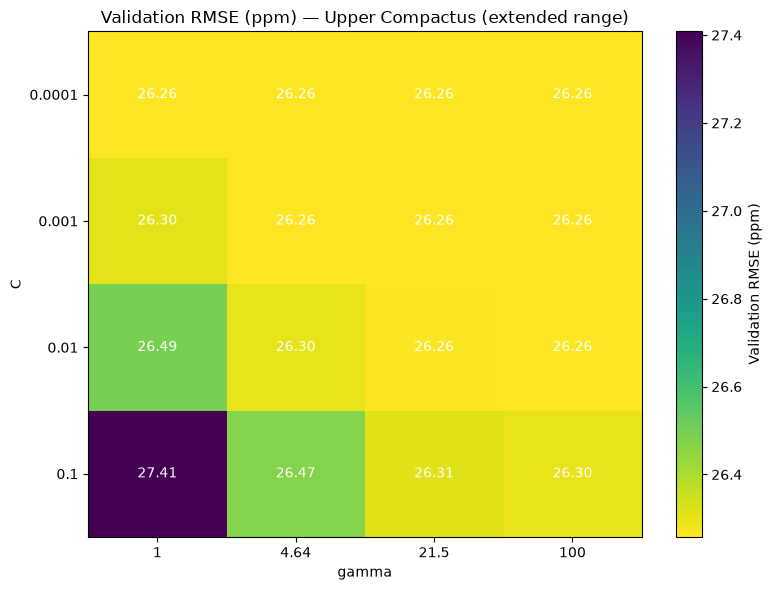

Unknown Room: grid best (C=10, gamma=0.1) vs final_params (C=10, gamma=0.1) -> match
Upper Compactus: grid best (C=0.0001, gamma=100) vs final_params (C=0.0001, gamma=100) -> match


In [118]:
# Stage 2 (Upper Compactus): the first grid's best cell was at the edge, so push C lower and gamma higher
best_params[UPPER_COMPACTUS] = svr_grid(
    UPPER_COMPACTUS,
    C_values=np.logspace(-4, -1, 4),       # 0.0001 - 0.1
    gamma_values=np.logspace(0, 2, 4),     # 1 - 100
    epsilon=0.5,
    label='(extended range)',
)

# Consistency check against the frozen values in Section 1
for sid, bp in best_params.items():
    fp = final_params[sid]
    same = np.isclose(bp['C'], fp['C']) and np.isclose(bp['gamma'], fp['gamma'])
    print(f"{sensor_names[sid]}: grid best (C={bp['C']:.4g}, gamma={bp['gamma']:.4g}) vs "
          f"final_params (C={fp['C']:.4g}, gamma={fp['gamma']:.4g}) -> {'match' if same else 'UPDATE final_params'}")

Unknown Room (extended gamma): best C=10, best gamma=0.1, RMSE=28.77 ppm (epsilon=0.1)


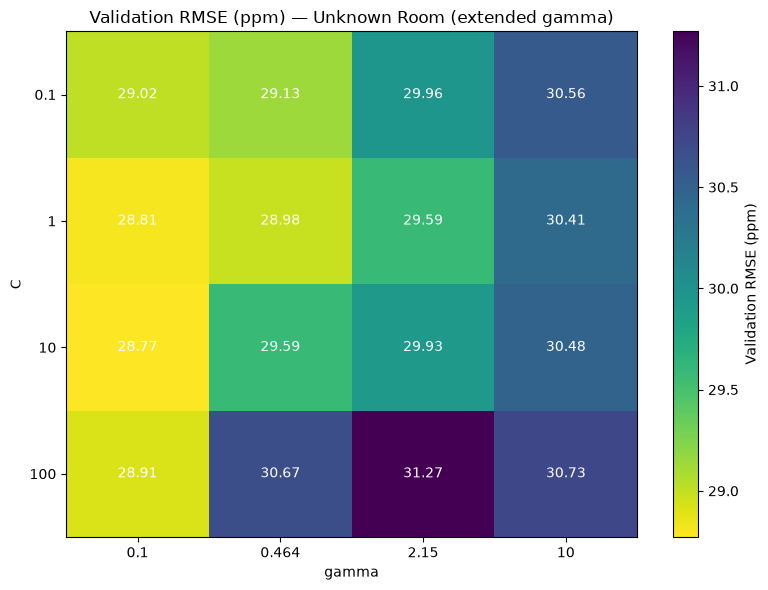

In [119]:
best_params[UNKNOWN_ROOM] = svr_grid(
    UNKNOWN_ROOM,
    C_values=np.logspace(-1, 2, 4),        # 0.1 - 100
    gamma_values=np.logspace(-1, 1, 4),    # 0.1 - 10 (overlaps the first grid at 0.1)
    epsilon=0.1,
    label='(extended gamma)',
)

### 7.4 Optimisation: epsilon sweep


Upper Compactus (C=0.0001, gamma=100):


  epsilon=0.01: RMSE=26.53 ppm
  epsilon=0.05: RMSE=26.50 ppm
  epsilon=0.1: RMSE=26.48 ppm
  epsilon=0.5: RMSE=26.26 ppm
  epsilon=1: RMSE=26.53 ppm
  epsilon=2: RMSE=26.53 ppm
  epsilon=5: RMSE=26.53 ppm

Unknown Room (C=10, gamma=0.1):
  epsilon=0.01: RMSE=28.78 ppm
  epsilon=0.05: RMSE=28.78 ppm
  epsilon=0.1: RMSE=28.77 ppm
  epsilon=0.5: RMSE=28.75 ppm
  epsilon=1: RMSE=28.73 ppm
  epsilon=2: RMSE=28.70 ppm
  epsilon=5: RMSE=28.64 ppm


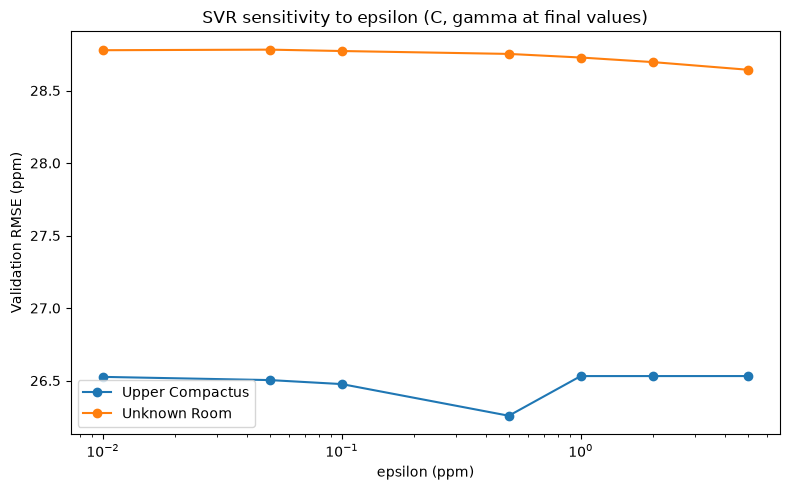

In [120]:
epsilon_values = [0.01, 0.05, 0.1, 0.5, 1, 2, 5]
eps_rmse = {}

for sid in sensor_names:
    C, gamma = final_params[sid]['C'], final_params[sid]['gamma']
    d = data[sid]
    eps_rmse[sid] = []
    print(f"\n{sensor_names[sid]} (C={C:.4g}, gamma={gamma:.4g}):")
    for eps in epsilon_values:
        pred = SVR(kernel='rbf', C=C, gamma=gamma, epsilon=eps).fit(d['X_train'], d['y_train']).predict(d['X_test'])
        rmse = root_mean_squared_error(d['y_test'], pred)
        eps_rmse[sid].append(rmse)
        print(f"  epsilon={eps}: RMSE={rmse:.2f} ppm")

plt.figure(figsize=(8, 5))
for sid in sensor_names:
    plt.plot(epsilon_values, eps_rmse[sid], marker='o', label=sensor_names[sid])
plt.xscale('log')
plt.xlabel('epsilon (ppm)')
plt.ylabel('Validation RMSE (ppm)')
plt.title('SVR sensitivity to epsilon (C, gamma at final values)')
plt.legend()
plt.tight_layout()
plt.show()

## 8. Final comparison

### 8.1 accuracy comparison

In [121]:
# Build the two remaining candidates: the optimised SVR (frozen final_params) and the mean predictor
for sid in sensor_names:
    fit_and_score(sid, 'SVR (optimised)', SVR(kernel='rbf', **final_params[sid]))
    fit_and_score(sid, 'Mean predictor', DummyRegressor(strategy='mean'))
    fit_and_score(sid, 'Median predictor', DummyRegressor(strategy='median'))

model_order = ['SVR (baseline)', 'SVR (optimised)', 'Linear Regression', 'Mean predictor','Median predictor']
roles = {
    'SVR (baseline)': 'Computational solution (baseline)',
    'SVR (optimised)': 'Optimisation',
    'Linear Regression': 'Alternative solution',
    'Mean predictor': 'Sanity check',
    'Median predictor': 'Sanity check',
}

rows = []
for sid in sensor_names:
    base_rmse = results[(sid, 'SVR (baseline)')]['rmse']
    for m in model_order:
        r = results[(sid, m)]
        rows.append({
            'Sensor': sensor_names[sid],
            'Model': m,
            'Role': roles[m],
            'RMSE (ppm)': r['rmse'],
            'MAE (ppm)': r['mae'],
            'R²': r['r2'],
            'Fit time (s)': r['fit_s'],
            'RMSE vs SVR baseline (%)': (r['rmse'] / base_rmse - 1) * 100,
        })
comparison = pd.DataFrame(rows)
comparison.round(3)

,Sensor,Model,Role,RMSE (ppm),MAE (ppm),R²,Fit time (s),RMSE vs SVR baseline (%)
0,Upper Compactus,SVR (baseline),Computational solution (baseline),32.256,26.370,-1.132,3.202,0.000
1,Upper Compactus,SVR (optimised),Optimisation,26.258,22.058,-0.413,3.795,-18.597
2,Upper Compactus,Linear Regression,Alternative solution,34.223,27.544,-1.400,0.002,6.097
3,Upper Compactus,Mean predictor,Sanity check,34.001,29.862,-1.369,0.000,5.409
4,Upper Compactus,Median predictor,Sanity check,26.531,22.336,-0.442,0.000,-17.749
5,Unknown Room,SVR (baseline),Computational solution (baseline),28.806,15.369,0.085,13.917,0.000
6,Unknown Room,SVR (optimised),Optimisation,28.643,15.144,0.096,9.897,-0.563
7,Unknown Room,Linear Regression,Alternative solution,29.584,18.114,0.035,0.003,2.703
8,Unknown Room,Mean predictor,Sanity check,30.205,17.074,-0.006,0.000,4.858
9,Unknown Room,Median predictor,Sanity check,30.651,16.776,-0.035,0.000,6.406


In [122]:
# Split each model's error into a level offset (bias) and the rest, and check whether it tracks the signal at all
rows = []
for sid in sensor_names:
    y = data[sid]['y_test']
    for m in model_order:
        p = preds[(sid, m)]
        err = y - p
        rows.append({'Sensor': sensor_names[sid], 'Model': m,
                     'Bias (ppm)': err.mean(),
                     'Error std (ppm)': err.std(),
                     'Corr(pred, actual)': np.corrcoef(p, y)[0, 1] if p.std() > 1e-9 else np.nan})
pd.DataFrame(rows).round(3)

,Sensor,Model,Bias (ppm),Error std (ppm),"Corr(pred, actual)"
0,Upper Compactus,SVR (baseline),-19.129,25.972,0.118
1,Upper Compactus,SVR (optimised),-14.191,22.092,-0.016
2,Upper Compactus,Linear Regression,-21.352,26.745,0.246
3,Upper Compactus,Mean predictor,-25.846,22.092,NaN
4,Upper Compactus,Median predictor,-14.691,22.092,NaN
5,Unknown Room,SVR (baseline),1.119,28.784,0.308
6,Unknown Room,SVR (optimised),1.414,28.608,0.314
7,Unknown Room,Linear Regression,-5.971,28.975,0.276
8,Unknown Room,Mean predictor,2.245,30.121,NaN
9,Unknown Room,Median predictor,5.673,30.121,NaN


In [123]:
# Why can R² be negative? Compare the CO2 level in the training and test periods.
for sid in sensor_names:
    d = data[sid]
    print(f"{sensor_names[sid]}: train mean={d['y_train'].mean():.1f} ppm (std {d['y_train'].std():.1f}), "
          f"test mean={d['y_test'].mean():.1f} ppm (std {d['y_test'].std():.1f})")

Upper Compactus: train mean=479.2 ppm (std 41.0), test mean=453.3 ppm (std 22.1)
Unknown Room: train mean=440.4 ppm (std 24.4), test mean=442.7 ppm (std 30.1)


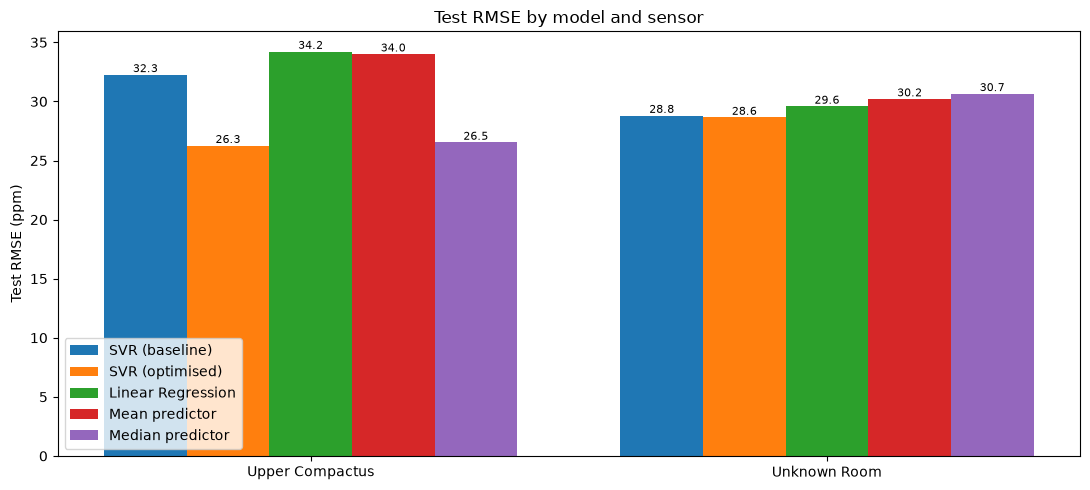

In [124]:
# RMSE by model, per sensor
fig, ax = plt.subplots(figsize=(11, 5))
width = 0.8 / len(model_order)
x = np.arange(len(sensor_names))
for k, m in enumerate(model_order):
    vals = [results[(sid, m)]['rmse'] for sid in sensor_names]
    bars = ax.bar(x + k * width, vals, width, label=m)
    ax.bar_label(bars, fmt='%.1f', fontsize=8)
ax.set_xticks(x + width * (len(model_order) - 1) / 2)
ax.set_xticklabels([sensor_names[sid] for sid in sensor_names])
ax.set_ylabel('Test RMSE (ppm)')
ax.set_title('Test RMSE by model and sensor')
ax.legend()
plt.tight_layout()
plt.show()

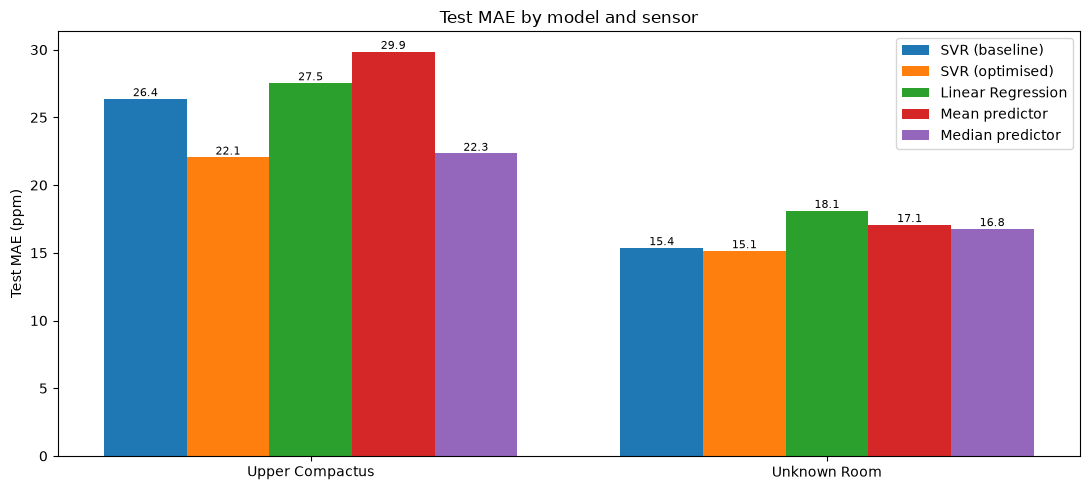

In [125]:
# MAE by model, per sensor (less dominated by rare CO2 spikes than RMSE)
fig, ax = plt.subplots(figsize=(11, 5))
for k, m in enumerate(model_order):
    vals = [results[(sid, m)]['mae'] for sid in sensor_names]
    bars = ax.bar(x + k * width, vals, width, label=m)
    ax.bar_label(bars, fmt='%.1f', fontsize=8)
ax.set_xticks(x + width * (len(model_order) - 1) / 2)
ax.set_xticklabels([sensor_names[sid] for sid in sensor_names])
ax.set_ylabel('Test MAE (ppm)')
ax.set_title('Test MAE by model and sensor')
ax.legend()
plt.tight_layout()
plt.show()

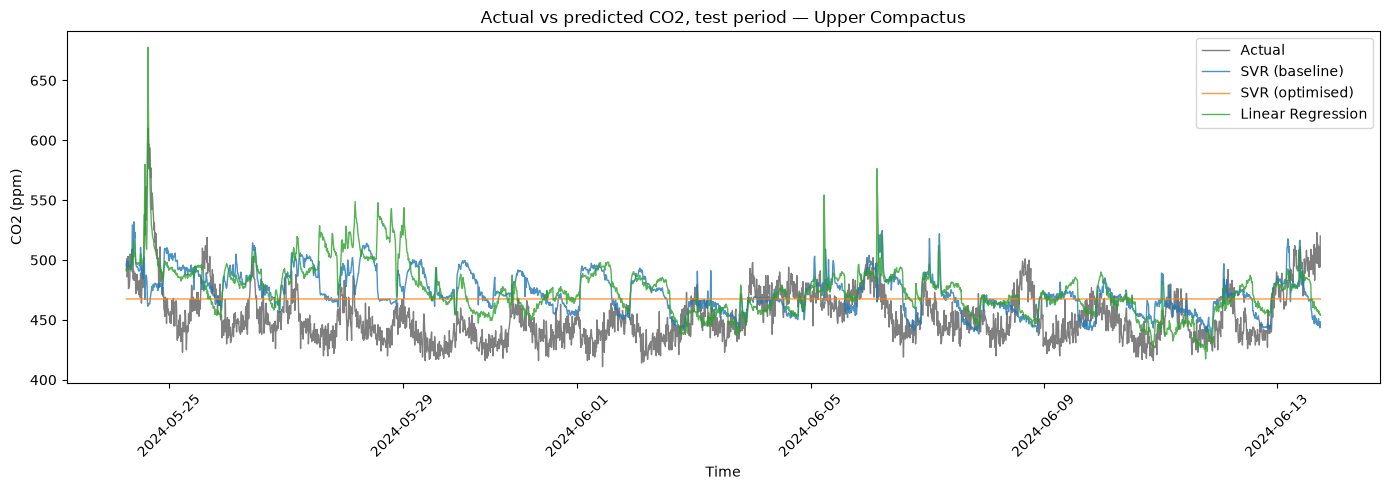

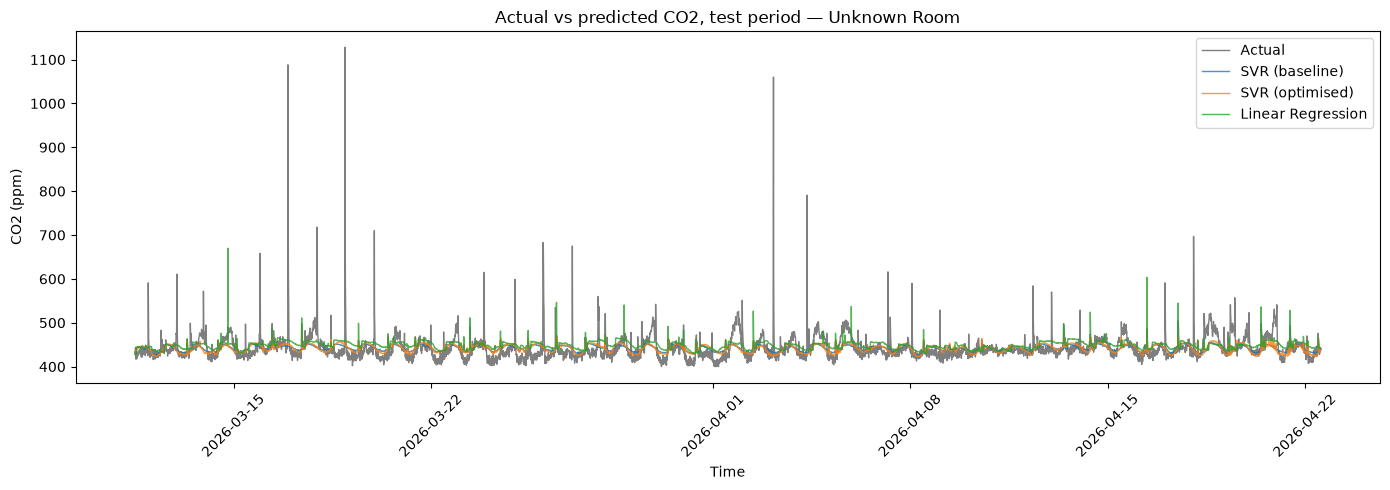

In [126]:
# The three main models against actual CO2 over the test period
def plot_model_overlay(sid, names):
    '''Actual CO2 and the predictions of several models over the test period for one sensor.'''
    d = data[sid]
    fig, ax = plt.subplots(figsize=(14, 5))
    ax.plot(d['test']['timestamp'], d['y_test'], label='Actual', color='black', alpha=0.5, linewidth=1)
    for n in names:
        ax.plot(d['test']['timestamp'], preds[(sid, n)], label=n, alpha=0.8, linewidth=1)
    ax.set_xlabel('Time')
    ax.set_ylabel('CO2 (ppm)')
    ax.set_title(f'Actual vs predicted CO2, test period — {sensor_names[sid]}')
    ax.legend()
    ax.tick_params(axis='x', rotation=45)
    plt.tight_layout()
    plt.show()


for sid in sensor_names:
    plot_model_overlay(sid, ['SVR (baseline)', 'SVR (optimised)', 'Linear Regression'])

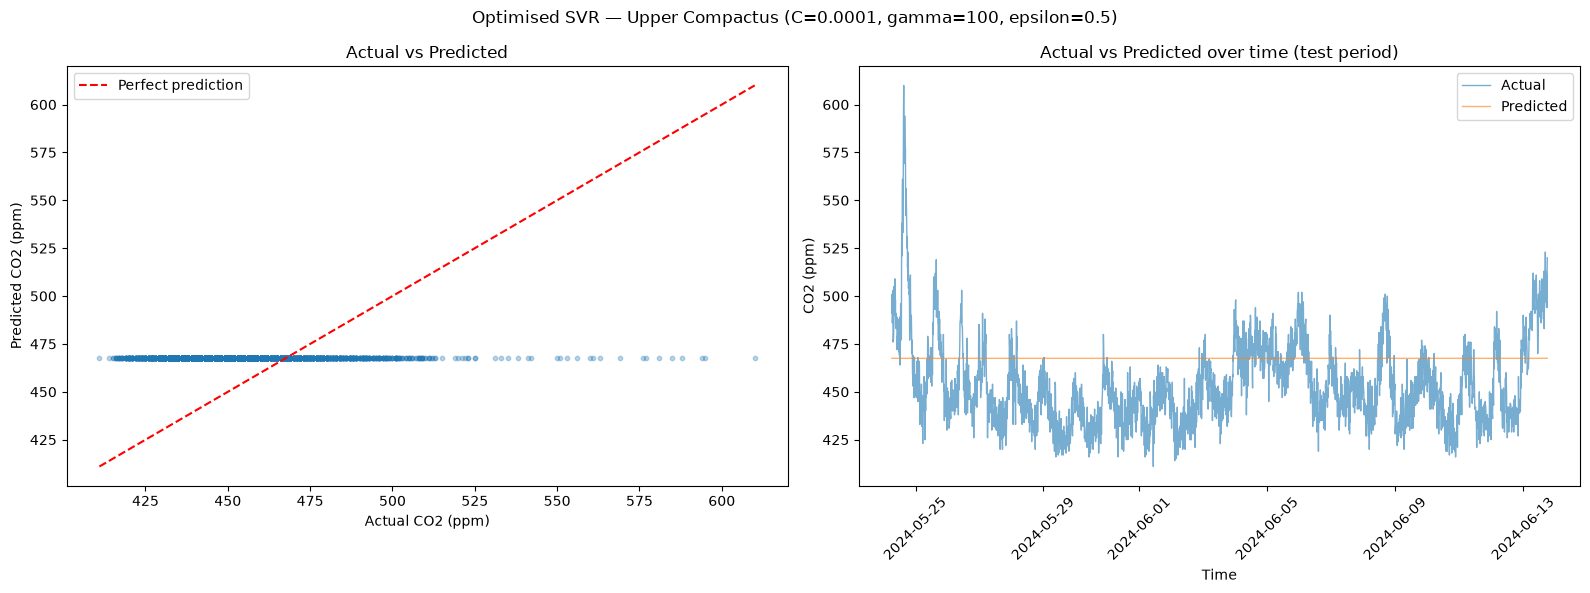

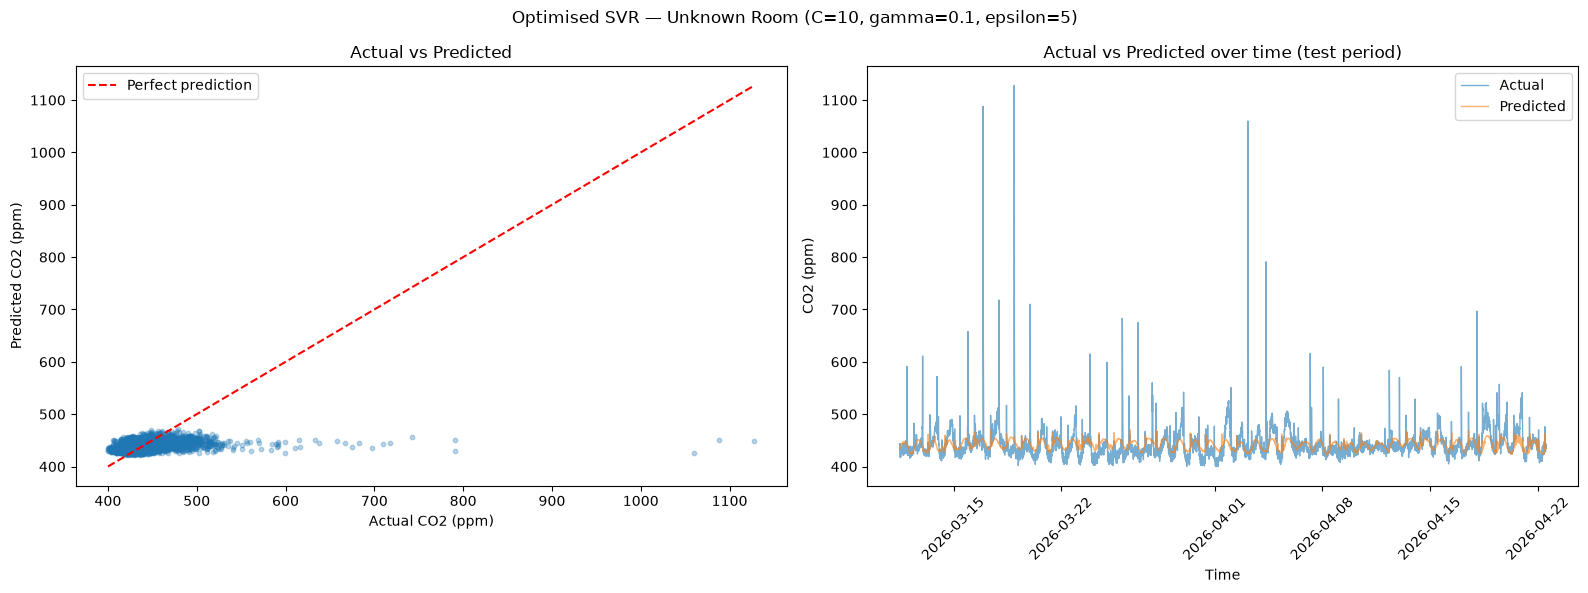

In [127]:
# Optimised model: actual vs predicted
for sid in sensor_names:
    p = final_params[sid]
    plot_actual_vs_pred(sid, 'SVR (optimised)',
                        suptitle=f"Optimised SVR — {sensor_names[sid]} "
                                 f"(C={p['C']:.4g}, gamma={p['gamma']:.4g}, epsilon={p['epsilon']})")

### 8.2 performance analysis

In [128]:
# Timing, support vectors and stored model size

# The three models whose cost is compared. Each entry builds a fresh, unfitted model for a sensor.
candidates = {
    'SVR (baseline)': lambda sid: SVR(kernel='rbf', **baseline_params),
    'SVR (optimised)': lambda sid: SVR(kernel='rbf', **final_params[sid]),
    'Linear Regression': lambda sid: LinearRegression(),
}


def time_call(fn, repeats=5):
    """Median wall-clock time (s) of fn() over several repeats.

    The median is used instead of a single run because one timing can be
    thrown off by other processes running on the machine.
    """
    times = []
    for _ in range(repeats):
        t0 = time.perf_counter()
        fn()
        times.append(time.perf_counter() - t0)
    return float(np.median(times))


perf_rows = []
for sid in sensor_names:
    d = data[sid]
    for name, make in candidates.items():
        # Fit time: build and fit a new model each repeat so every run does the same work
        fit_t = time_call(lambda: make(sid).fit(d['X_train'], d['y_train']), repeats=3)

        # Prediction time: fit once, then time predict() on the test inputs
        model = make(sid).fit(d['X_train'], d['y_train'])
        pred_t = time_call(lambda: model.predict(d['X_test']), repeats=5)

        perf_rows.append({
            'Sensor': sensor_names[sid],
            'Model': name,
            'Fit time (s)': fit_t,
            'Predict time (s)': pred_t,
            # An SVR keeps its support vectors, so its size and prediction cost grow with them.
            # Linear regression only keeps one coefficient per input.
            'Support vectors': len(model.support_) if hasattr(model, 'support_') else np.nan,
            # Size of the fitted model when saved, as a proxy for the memory needed to deploy it
            'Stored model size (KB)': len(pickle.dumps(model)) / 1024,
        })

perf_table = pd.DataFrame(perf_rows)
perf_table.round(4)

,Sensor,Model,Fit time (s),Predict time (s),Support vectors,Stored model size (KB)
0,Upper Compactus,SVR (baseline),3.2281,1.4877,11007.0,903.9443
1,Upper Compactus,SVR (optimised),3.7494,1.6634,10870.0,892.6992
2,Upper Compactus,Linear Regression,0.0015,0.0003,NaN,0.5498
3,Unknown Room,SVR (baseline),13.8674,5.6356,21716.0,1782.4258
4,Unknown Room,SVR (optimised),10.4197,4.1023,14847.0,1218.9375
5,Unknown Room,Linear Regression,0.0033,0.0002,NaN,0.5498


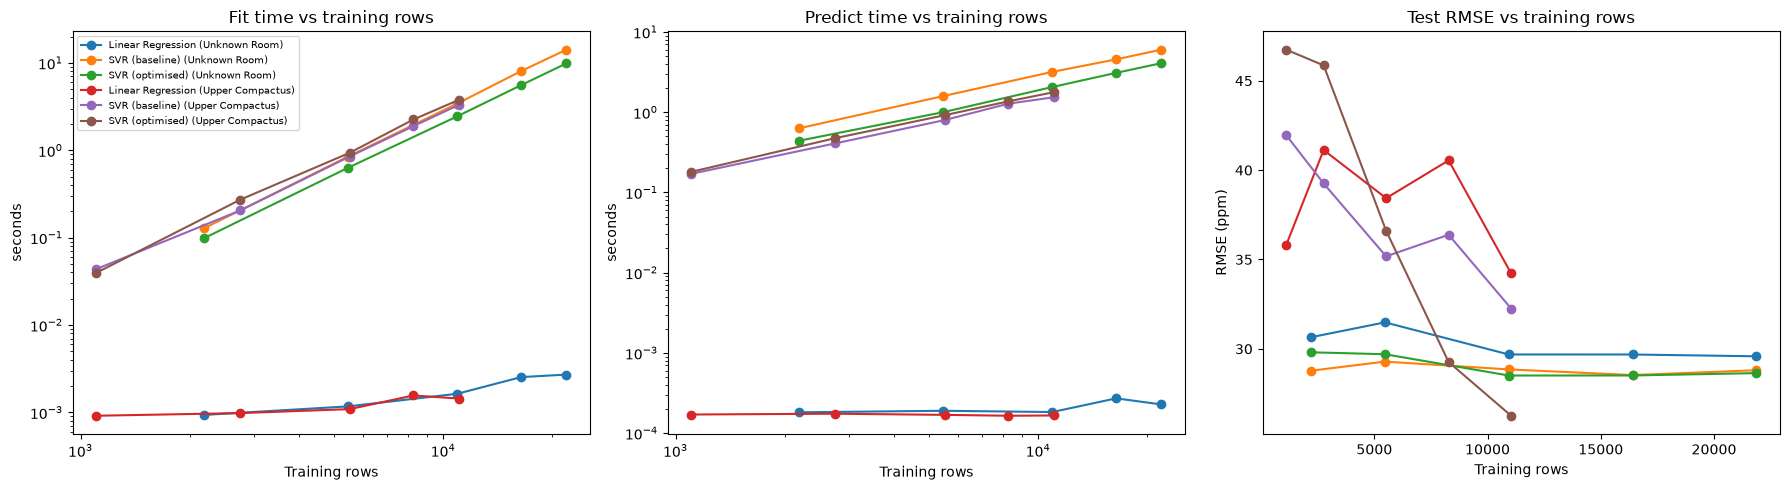

Unknown Room, Linear Regression: fit time scales roughly as n^0.49
Unknown Room, SVR (baseline): fit time scales roughly as n^2.05
Unknown Room, SVR (optimised): fit time scales roughly as n^2.00
Upper Compactus, Linear Regression: fit time scales roughly as n^0.23
Upper Compactus, SVR (baseline): fit time scales roughly as n^1.89
Upper Compactus, SVR (optimised): fit time scales roughly as n^1.97


In [129]:
#how cost and accuracy change with the amount of training data

fracs = [0.1, 0.25, 0.5, 0.75, 1.0]   # share of the training rows used
scale_rows = []

for sid in sensor_names:
    d = data[sid]
    n_full = len(d['y_train'])
    for frac in fracs:
        n = int(n_full * frac)
        # Keep the most recent n rows (not a random sample) so the training data
        # still ends just before the test period, as in the main experiment
        X_sub, y_sub = d['X_train'][-n:], d['y_train'][-n:]

        for name, make in candidates.items():
            model = make(sid)

            t0 = time.perf_counter()
            model.fit(X_sub, y_sub)
            fit_t = time.perf_counter() - t0

            t0 = time.perf_counter()
            pred = model.predict(d['X_test'])
            pred_t = time.perf_counter() - t0

            scale_rows.append({
                'Sensor': sensor_names[sid], 'Model': name, 'n_train': n,
                'fit_s': fit_t, 'predict_s': pred_t,
                'rmse': root_mean_squared_error(d['y_test'], pred),
            })

scaling = pd.DataFrame(scale_rows)

# Log-log axes for the timings: a straight line means cost follows a power law in n
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for (sensor, name), g in scaling.groupby(['Sensor', 'Model']):
    axes[0].loglog(g['n_train'], g['fit_s'], marker='o', label=f'{name} ({sensor})')
    axes[1].loglog(g['n_train'], g['predict_s'], marker='o', label=f'{name} ({sensor})')
    axes[2].plot(g['n_train'], g['rmse'], marker='o', label=f'{name} ({sensor})')

axes[0].set_title('Fit time vs training rows')
axes[1].set_title('Predict time vs training rows')
axes[2].set_title('Test RMSE vs training rows')
for ax, ylabel in zip(axes, ['seconds', 'seconds', 'RMSE (ppm)']):
    ax.set_xlabel('Training rows')
    ax.set_ylabel(ylabel)
axes[0].legend(fontsize=7)
plt.tight_layout()
plt.show()

# Slope of the log-log line gives the empirical exponent k in: fit time ~ n^k
for (sensor, name), g in scaling.groupby(['Sensor', 'Model']):
    k = np.polyfit(np.log(g['n_train']), np.log(g['fit_s']), 1)[0]
    print(f"{sensor}, {name}: fit time scales roughly as n^{k:.2f}")

In [130]:
# Operation counts, arithmetic intensity and a profile
# These are order-of-magnitude estimates, not exact counts.

p = len(features)                         # number of inputs
flops_per_kernel_eval = 3 * p + 3         # squared distance (about 3p flops) plus the exponential
bytes_per_kernel_eval = 2 * p * 8         # two float64 input vectors read if the value is not cached

# Arithmetic intensity = flops per byte moved. A low value means the method is limited
# by memory access rather than by arithmetic.
print(f"Arithmetic intensity of one RBF kernel evaluation: about "
      f"{flops_per_kernel_eval / bytes_per_kernel_eval:.2f} flop/byte")

for sid in sensor_names:
    d = data[sid]
    n, n_test = len(d['y_train']), len(d['y_test'])
    n_sv = len(models[(sid, 'SVR (baseline)')].support_)

    print(f"\n{sensor_names[sid]} (n={n}, p={p}, test rows={n_test}, support vectors={n_sv}):")
    # The solver needs kernel values between pairs of training points: about n^2 / 2 pairs per pass,
    # and it makes many passes, so this is a lower bound for the whole fit
    print(f"  SVR fit, one pass over the kernel matrix: {0.5 * n * n * flops_per_kernel_eval:.2e} flops")
    # Prediction needs one kernel value per (support vector, test row) pair
    print(f"  SVR predict: {n_sv * n_test * flops_per_kernel_eval:.2e} flops")
    # Linear regression: about 2np^2 for the normal equations plus (2/3)p^3 for solving them
    print(f"  Linear regression fit: {2 * n * p ** 2 + (2 / 3) * p ** 3:.2e} flops, "
          f"predict: {2 * n_test * p:.2e} flops")

# Profile one baseline SVR fit to see where the time is spent
profiler = cProfile.Profile()
profiler.enable()
SVR(kernel='rbf', **baseline_params).fit(data[UPPER_COMPACTUS]['X_train'],
                                         data[UPPER_COMPACTUS]['y_train'])
profiler.disable()

stats = pstats.Stats(profiler)
_ = stats.strip_dirs().sort_stats('cumulative').print_stats(6) 

Arithmetic intensity of one RBF kernel evaluation: about 0.21 flop/byte

Upper Compactus (n=11040, p=9, test rows=2760, support vectors=11007):
  SVR fit, one pass over the kernel matrix: 1.83e+09 flops
  SVR predict: 9.11e+08 flops
  Linear regression fit: 1.79e+06 flops, predict: 4.97e+04 flops

Unknown Room (n=21876, p=9, test rows=5470, support vectors=21716):
  SVR fit, one pass over the kernel matrix: 7.18e+09 flops
  SVR predict: 3.56e+09 flops
  Linear regression fit: 3.54e+06 flops, predict: 9.85e+04 flops
         1376 function calls in 3.302 seconds

   Ordered by: cumulative time
   List reduced from 202 to 6 due to restriction <6>

   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
        2    0.000    0.000    3.302    1.651 interactiveshell.py:3786(run_code)
        2    0.000    0.000    3.302    1.651 {built-in method builtins.exec}
        1    0.000    0.000    3.302    3.302 base.py:1381(wrapper)
        1    0.000    0.000    3.302    3.302 _b

In [131]:
# Robustness to the split point
# Moves the train/test boundary to see whether the model ranking depends on where the cut falls.

def split_scores(sid, frac):
    """Test RMSE (ppm) of each candidate model when the first `frac` of the data is used for training."""
    sub = df_model[df_model['sensorid'] == sid].sort_values('timestamp')
    k = int(len(sub) * frac)
    train, test = sub.iloc[:k], sub.iloc[k:]

    # Scaler fitted on the training rows only, as in the main experiment
    scaler = StandardScaler()
    X_tr = scaler.fit_transform(train[features])
    X_te = scaler.transform(test[features])

    out = {}
    for name, make in candidates.items():
        pred = make(sid).fit(X_tr, train[TARGET]).predict(X_te)
        out[name] = root_mean_squared_error(test[TARGET], pred)

    # Reference: always predict the training mean
    out['Mean predictor'] = root_mean_squared_error(test[TARGET], np.full(len(test), train[TARGET].mean()))
    return out


split_rows = [{'Sensor': sensor_names[sid], 'Train fraction': f, **split_scores(sid, f)}
              for sid in sensor_names for f in [0.6, 0.7, 0.8, 0.9]]
pd.DataFrame(split_rows).round(2)

,Sensor,Train fraction,SVR (baseline),SVR (optimised),Linear Regression,Mean predictor
0,Upper Compactus,0.6,38.45,43.42,39.28,41.05
1,Upper Compactus,0.7,36.27,39.47,37.75,39.35
2,Upper Compactus,0.8,32.26,26.26,34.22,34.00
3,Upper Compactus,0.9,20.58,20.88,21.89,27.44
4,Unknown Room,0.6,29.45,30.06,28.62,29.98
5,Unknown Room,0.7,30.22,29.97,30.44,31.63
6,Unknown Room,0.8,28.81,28.64,29.58,30.20
7,Unknown Room,0.9,25.83,25.52,26.18,27.52


## 9. Residuals

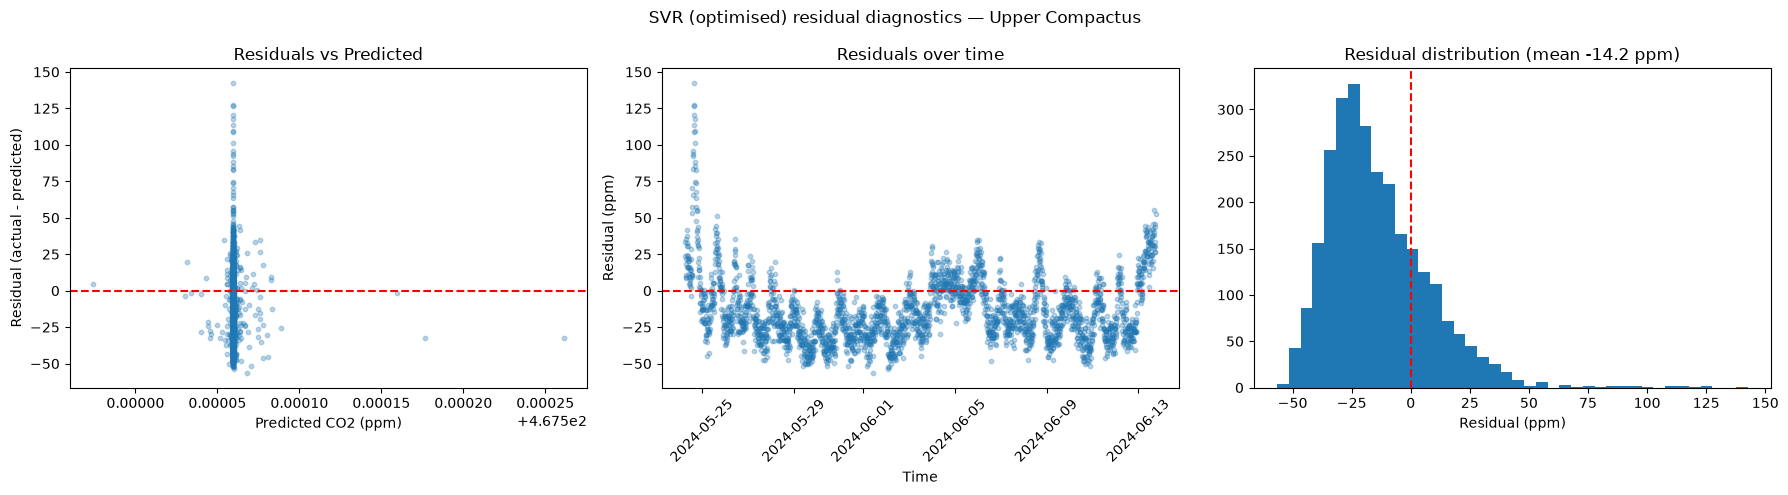

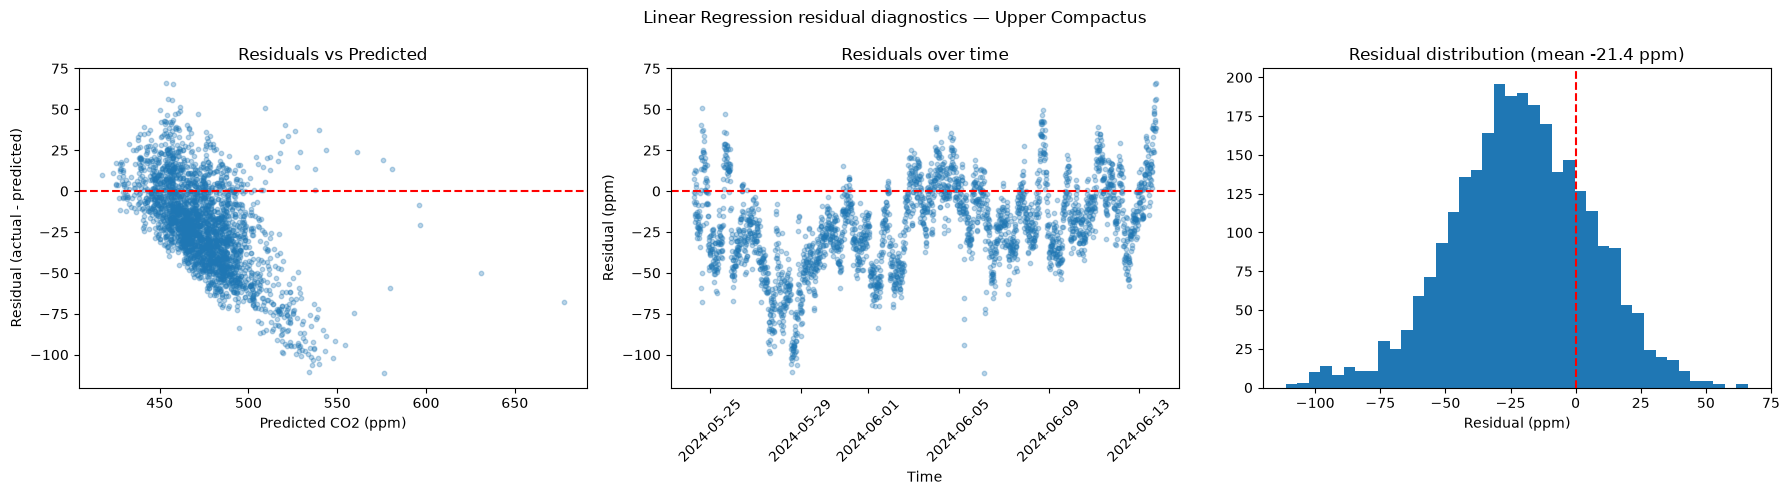

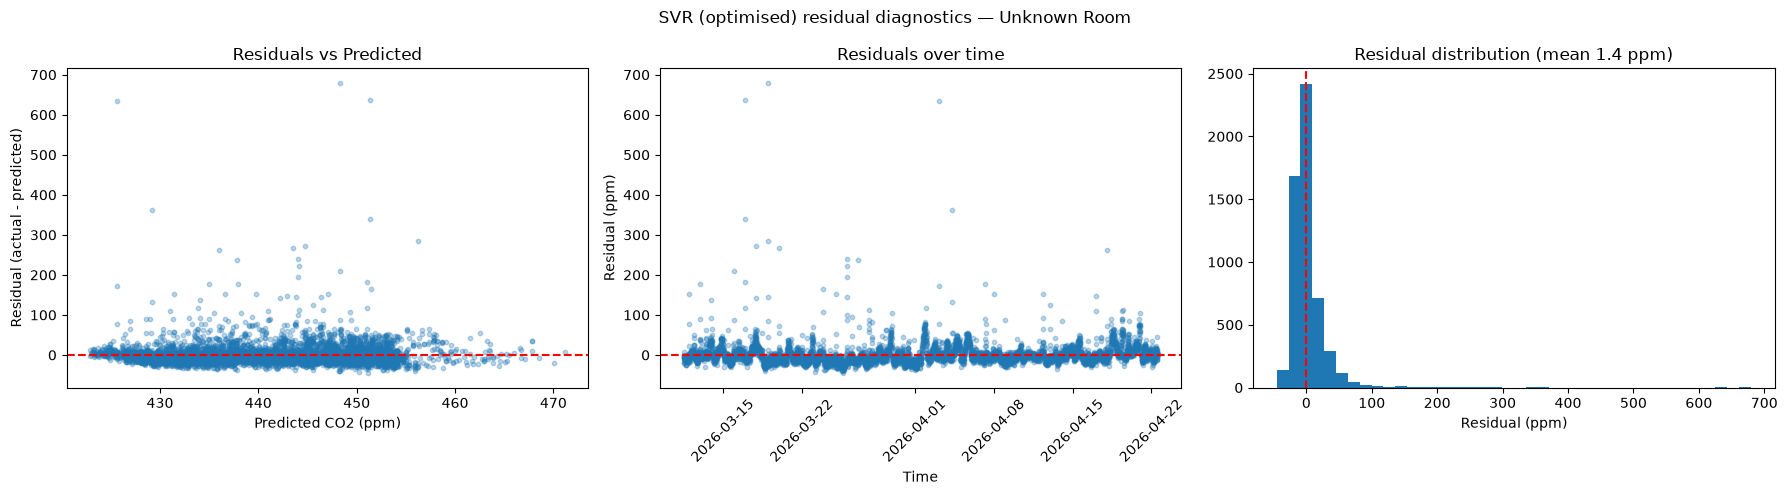

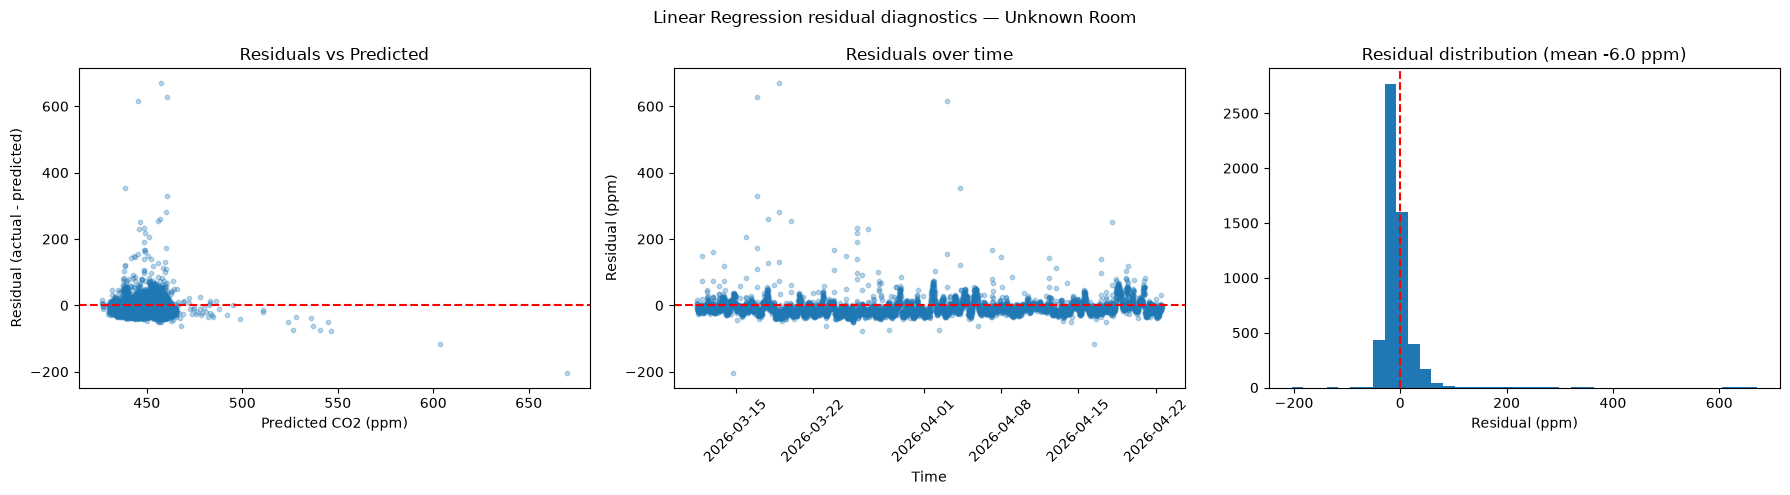

In [132]:
def residual_plots(sid, name):
    '''Residuals vs predicted, residuals over time and residual histogram for one fitted model.'''
    d = data[sid]
    pred = preds[(sid, name)]
    residuals = d['y_test'] - pred

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    axes[0].scatter(pred, residuals, alpha=0.3, s=10)
    axes[0].axhline(0, color='red', linestyle='--')
    axes[0].set_xlabel('Predicted CO2 (ppm)')
    axes[0].set_ylabel('Residual (actual - predicted)')
    axes[0].set_title('Residuals vs Predicted')

    axes[1].scatter(d['test']['timestamp'], residuals, alpha=0.3, s=10)
    axes[1].axhline(0, color='red', linestyle='--')
    axes[1].set_xlabel('Time')
    axes[1].set_ylabel('Residual (ppm)')
    axes[1].set_title('Residuals over time')
    axes[1].tick_params(axis='x', rotation=45)

    axes[2].hist(residuals, bins=40)
    axes[2].axvline(0, color='red', linestyle='--')
    axes[2].set_xlabel('Residual (ppm)')
    axes[2].set_title(f'Residual distribution (mean {residuals.mean():.1f} ppm)')

    fig.suptitle(f'{name} residual diagnostics — {sensor_names[sid]}')
    plt.tight_layout()
    plt.show()


for sid in sensor_names:
    for name in ['SVR (optimised)', 'Linear Regression']:
        residual_plots(sid, name)